# <center>🎓 Лекция 3. Как машина учится: понятия и типы машинного обучения</center>
## <center>机器如何学习：核心概念与类型</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 2 — Основы машинного обучения · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. формулировать определение обучения по Митчеллу (задача T, опыт E, мера P) для конкретной прикладной задачи;<br>2. отличать признаки от меток и собирать обучающую таблицу;<br>3. уверенно различать обучение с учителем (классификация, регрессия), без учителя и с подкреплением — с примерами из жизни;<br>4. объяснять, зачем делить данные на обучающую и тестовую выборки, и что такое утечка данных;<br>5. различать недообучение и переобучение на графиках;<br>6. пользоваться каркасом scikit-learn: fit → predict → score.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Что значит «учиться»: определение Митчелла <i>(10 мин)</i><br>• Признаки, метки, обучающая таблица <i>(15 мин)</i><br>• Три типа машинного обучения <i>(20 мин)</i><br>• Обучающая и тестовая выборки, утечка данных <i>(20 мин)</i><br>• Обобщение: недо- и переобучение <i>(10 мин)</i><br>• Каркас scikit-learn и цикл ML-проекта <i>(10 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> scikit-learn, pandas, matplotlib; Iris dataset.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


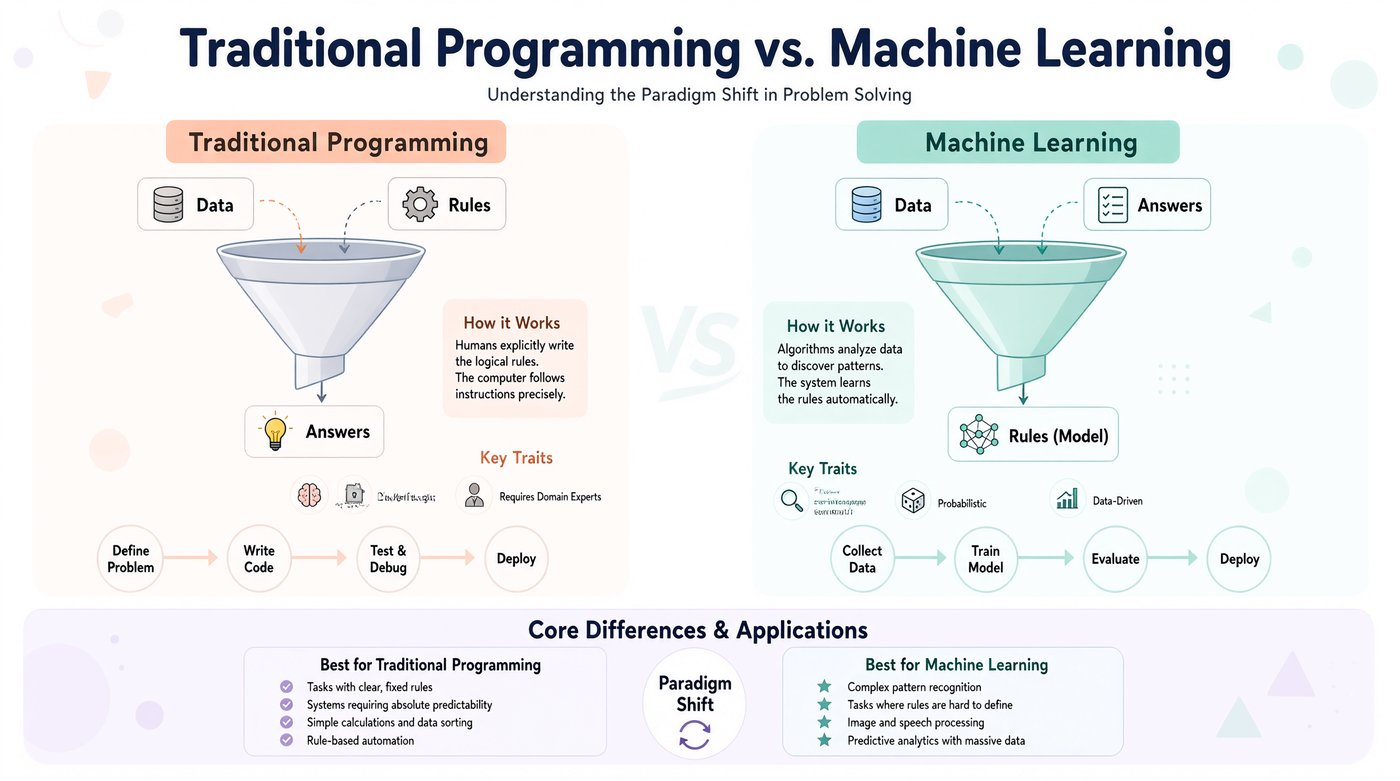

## 1. Что значит «учиться»: определение, которое снимает магию

В лекции 1 мы почувствовали разницу «правила vs обучение» на кухонной аналогии.
Традиционное программирование и машинное обучение решают задачи по-разному.

- **Традиционная программа:** Человек пишет чёткие правила. Программа получает данные и правила, а выдаёт ответ.  
  *(Пример: калькулятор. Мы задаём формулу, он считает.)*
- **Машинное обучение (МО):** Человек даёт программе данные и правильные ответы. Программа **сама находит правила** (создаёт модель).  
  *(Пример: фильтр спама. Мы показываем тысячи писем с пометками "спам" или "не спам", и модель сама учится замечать подозрительные слова.)*

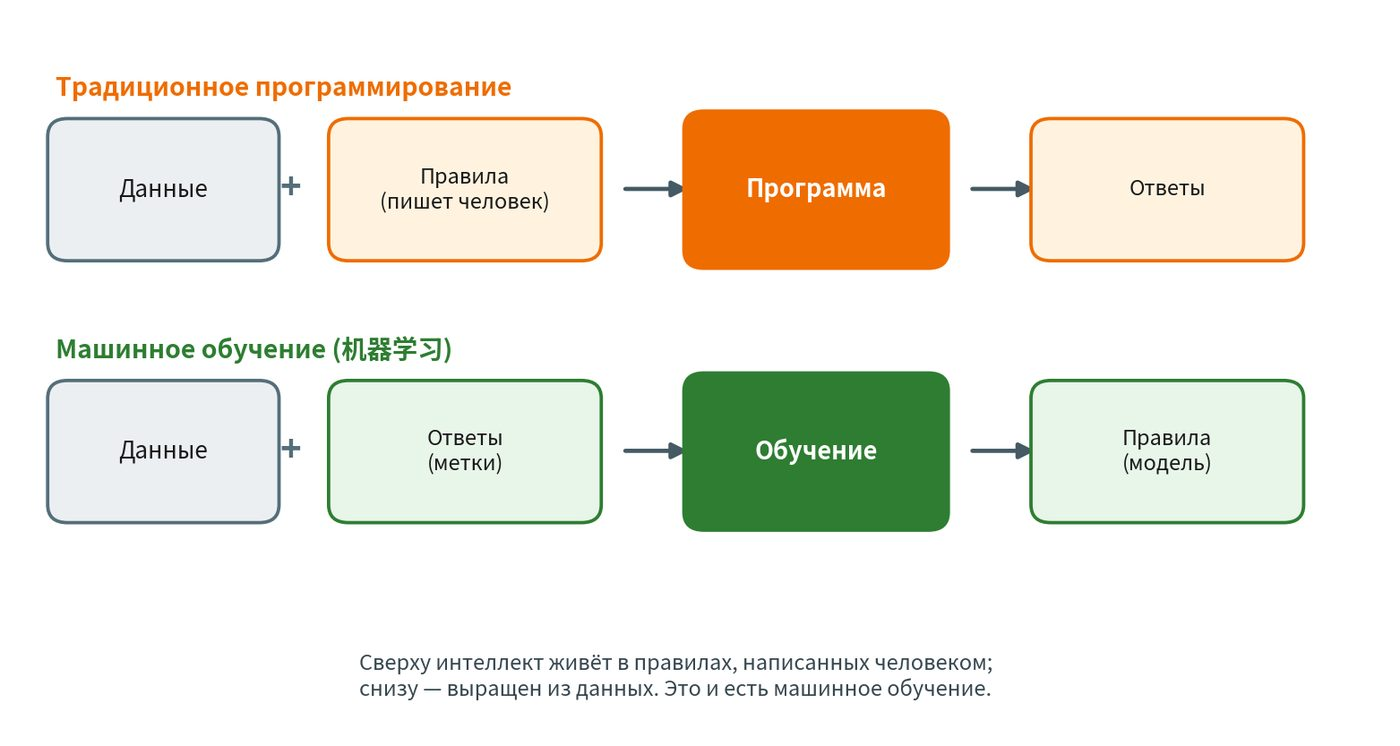  
*Рис. 1. Сравнение традиционного программирования и машинного обучения.*

> 💡 **Аналогия:**  
> Традиционное программирование — это как дать студенту формулу для решения задачи.  
> Машинное обучение — это как дать студенту 100 решённых задач и попросить его самого вывести формулу.

Теперь — формальное определение, которое используют в учебниках (Том Митчелл, 1997):


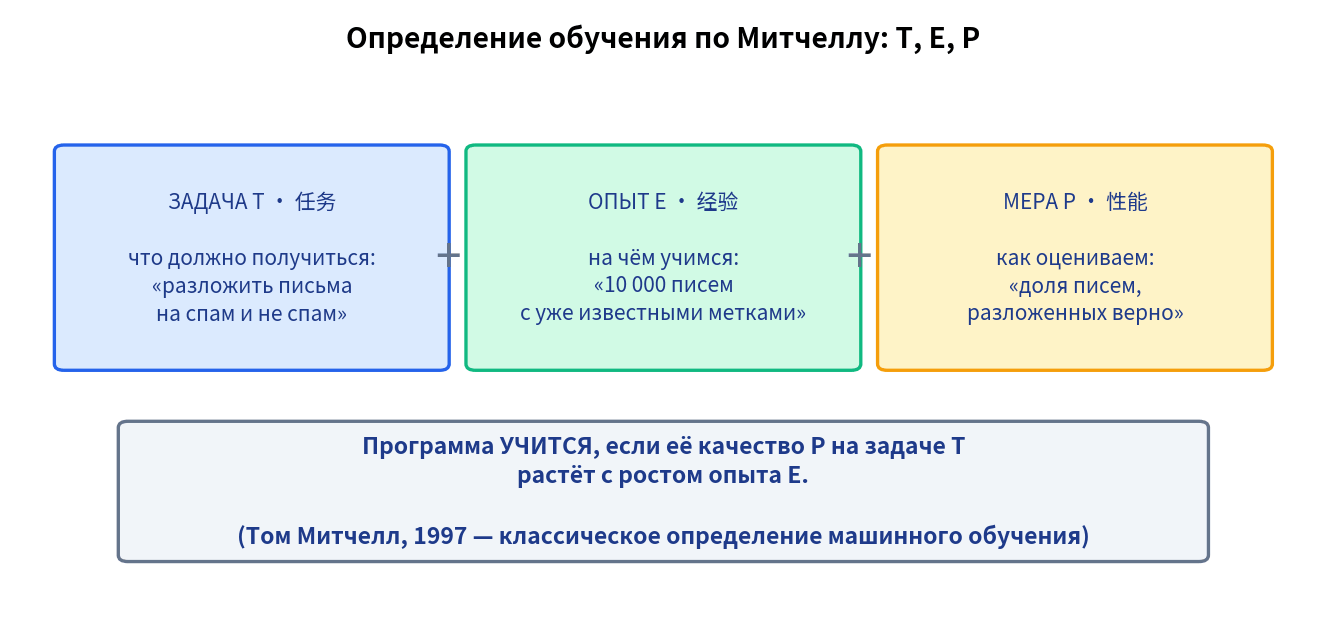

> **Программа обучается на опыте $E$ относительно задачи $T$ и меры качества $P$, если её качество на задаче $T$, измеренное мерой $P$, улучшается с ростом опыта $E$.**

Три буквы делают определение рабочим инструментом. Проверим на спам-фильтре:

| Буква | Спам-фильтр | Оплата лицом | Рекомендации Douyin |
|---|---|---|---|
| **T** — задача | разложить письма на спам/не спам | подтвердить, что это владелец карты | выбрать видео для ленты |
| **E** — опыт | 10 000 писем с метками | миллионы пар «фото → согласие/отказ» | история просмотров миллионов пользователей |
| **P** — мера | доля верно разложенных писем | доля верных подтверждений при низком уровне чужих | доля досмотренных видео |

**❓ Вопрос на закрепление:** сформулируйте T, E, P для системы, предсказывающей оценку студента на экзамене по его активности в LMS. *(T — предсказать балл; E — истории прошлых студентов с итоговыми баллами; P — средняя ошибка предсказания.)*

Заметили: в определении нет слова «нейросеть». **Машинное обучение — это про учение из опыта, а не про конкретный алгоритм.** Нейросети — лишь один из инструментов (лекции 5–8).


# Машинное и глубинное обучение

**Машинное обучение** — это подход, при котором модель учится находить закономерности в данных, чтобы делать предсказания или принимать решения без явного программирования каждого правила.

Основные типы задач в машинном обучении:

- **Классификация** — определить класс объекта;
- **Регрессия** — предсказать числовое значение;
- **Кластеризация** — найти группы похожих объектов;
- **Рекомендации, прогнозирование, обнаружение аномалий**.

Эти типы задач мы обсудим подробнее в этом уроке.

## А что такое глубинное обучение?

**Глубинное обучение** (*Deep Learning*) — это направление машинного обучения, основанное на нейронных сетях: многослойных моделях, которые способны самостоятельно извлекать сложные представления из данных.

Особенно полезно глубинное обучение, когда данные сложные и неструктурированные:

- изображения и видео;
- текст и речь;
- аудио;
- графы;
- мультимодальные данные.

Например, нейронная сеть может сама научиться выделять из изображения сначала простые признаки, затем более сложные — вплоть до объектов и их частей.

 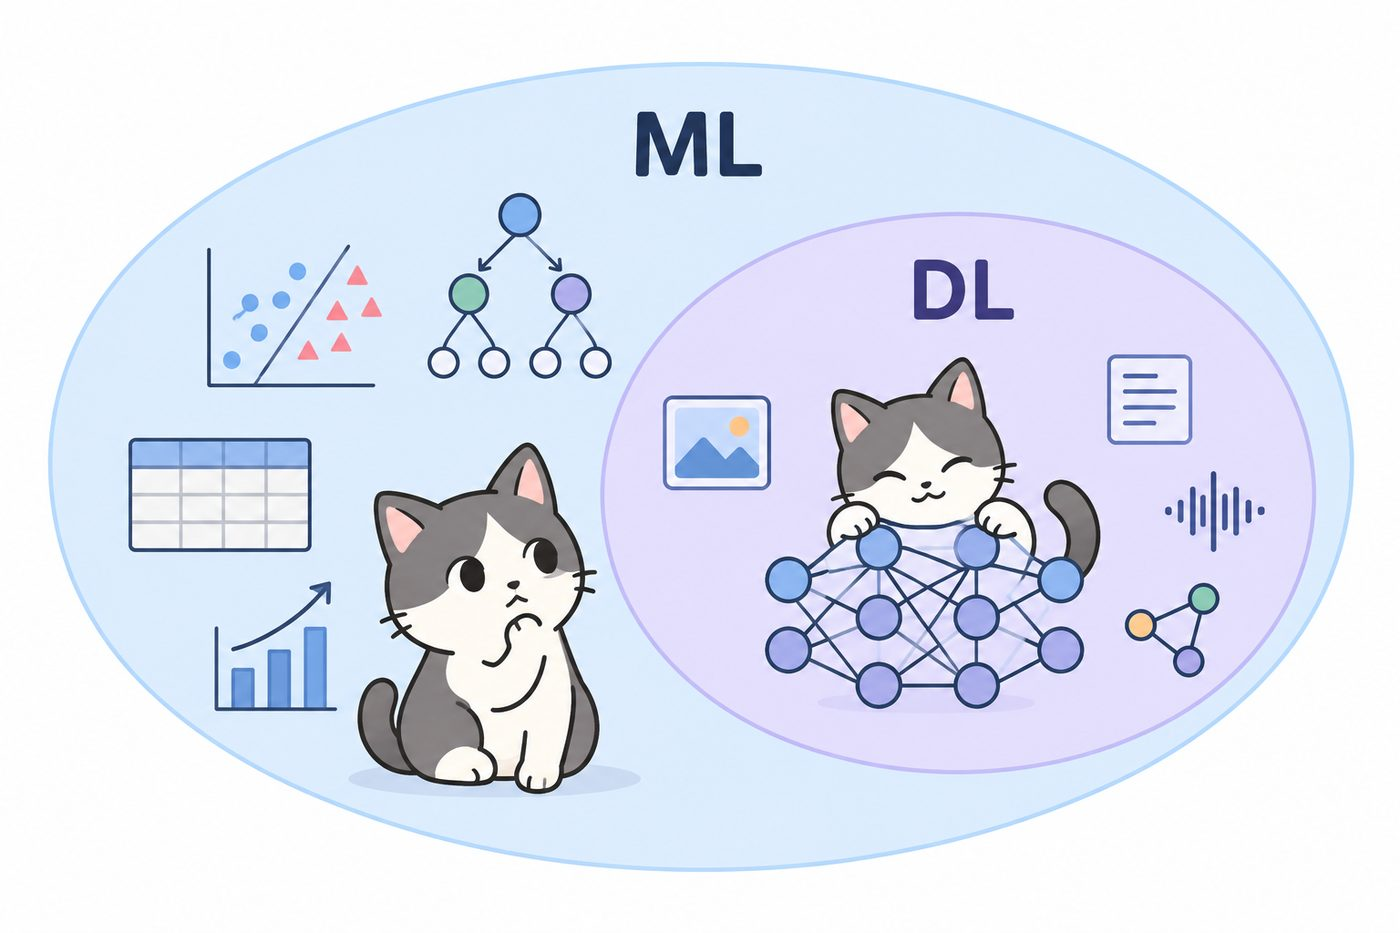
> *Для табличных данных классическое машинное обучение часто прекрасно работает и без глубоких нейронных сетей. Деревья решений, случайный лес, градиентный бустинг и другие методы могут быть очень эффективны на данных, где признаки уже представлены в виде структурированных столбцов.*


# Три типа задач машинного обучения

Все задачи ИИ можно разделить на три большие группы в зависимости от того, какой ответ мы хотим получить.

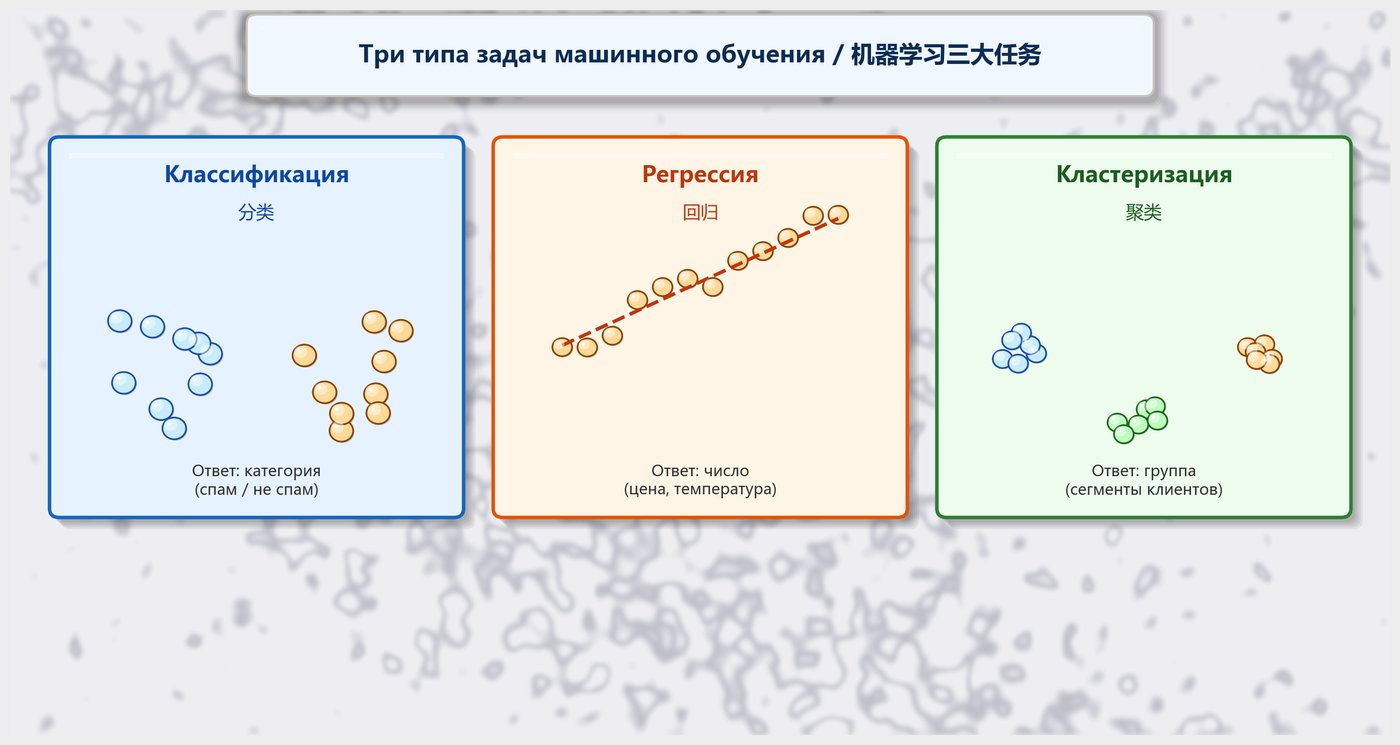

## 1. Классификация (分类)

**Вопрос:** «К какому классу относится объект?»
**Ответ:** Категория (метка).

**Примеры:**
- Спам или не спам?
- Кошка или собака на фото?
- Болен пациент или здоров?

Модель учится проводить **границу** между классами.

## 2. Регрессия (回归)

**Вопрос:** «Какое числовое значение будет у объекта?»
**Ответ:** Число.

**Примеры:**
- Сколько будет стоить эта квартира?
- Какая будет завтра температура?
- Сколько времени займёт доставка?

Модель учится проводить **линию тренда** через данные.

## 3. Кластеризация (聚类)

**Вопрос:** «Какие объекты похожи друг на друга?»
**Ответ:** Группа (кластер).

**Примеры:**
- Сегментация клиентов (кто покупает часто, кто редко).
- Группировка новостей по темам.
- Поиск аномалий (мошеннических транзакций).

Здесь у нас **нет правильных ответов** заранее. Модель сама ищет структуру в данных.

# Задача классификации

Одни из самых распространённых задач в машинном обучении — классификация и регрессия. Начнём с классификации.

В задаче **классификации** целевая переменная принимает значения из заранее заданного набора классов. Иными словами, модель должна определить, к какому классу относится объект.

## Примеры бинарной (двухклассовой) классификации

В этом случае возможны только два класса:

- вернёт клиент кредит или нет;
- уйдёт клиент из компании или останется;
- болен пациент или здоров;
- является письмо спамом или нет.

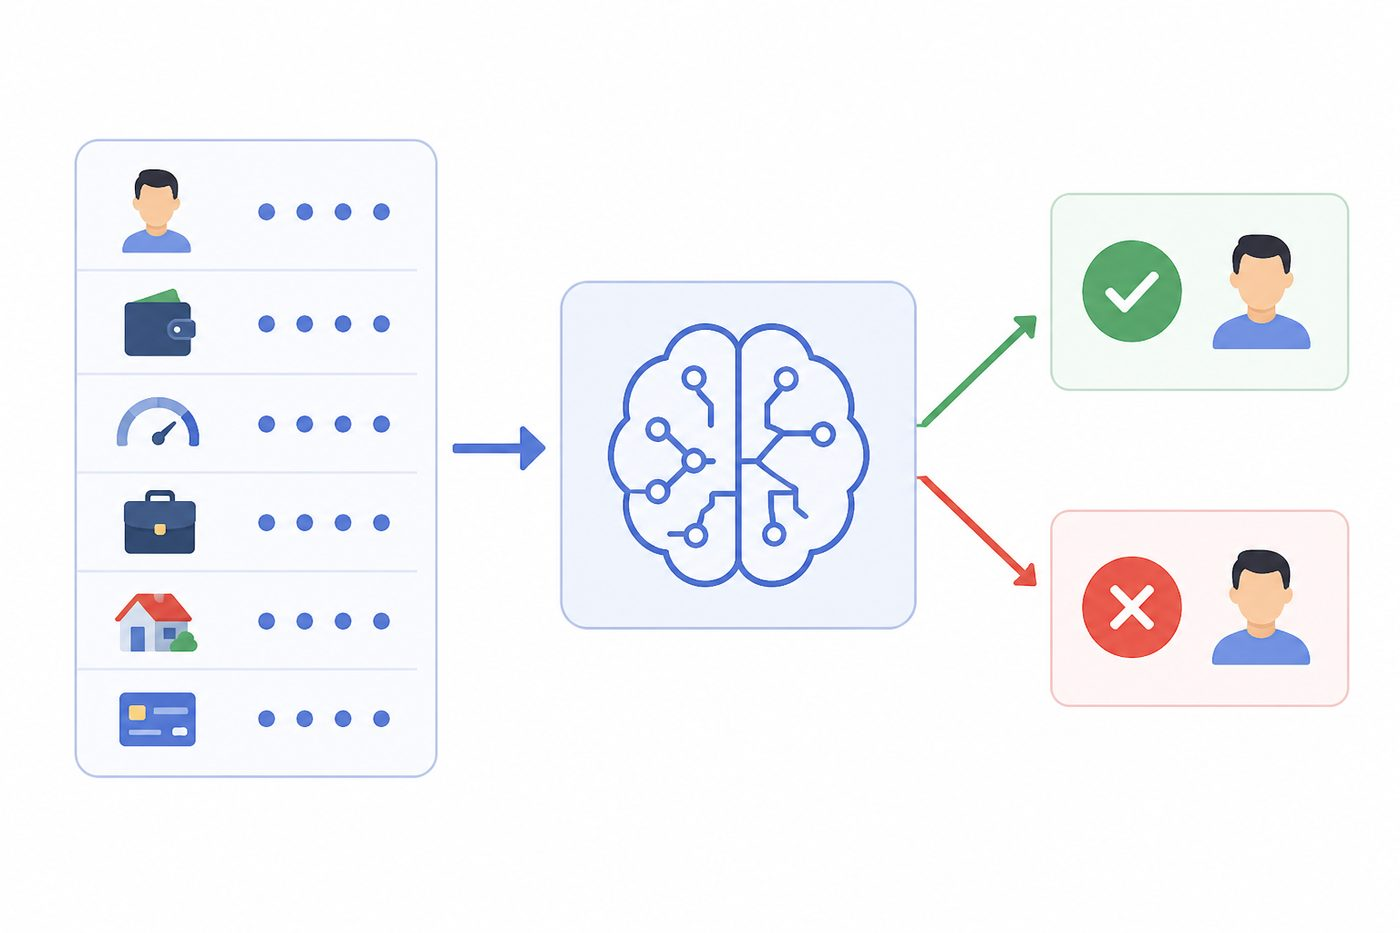

## Классификация с несколькими классами

Классов может быть и больше двух:

- определение оценки школьника за экзамен (от 2 до 5);
- определение уровня доверия к клиенту (например, от 1 до 10);
- определение объекта на изображении — выбор одного из 1000 возможных классов.

Главное свойство задачи классификации — **конечное множество возможных ответов**, из которых модель должна выбрать подходящий.

> **P.S.** Некоторые задачи можно сформулировать и как классификацию, и как регрессию. Например, уровень доверия к клиенту от 1 до 10 можно рассматривать как выбор одного из 10 классов или как предсказание числового значения.


# Задача регрессии

Теперь рассмотрим другой распространённый тип задач машинного обучения — регрессию.

В задачах **регрессии** модель предсказывает числовое значение. В отличие от классификации, здесь ответ не выбирается из конечного набора классов, а может принимать любое значение из некоторого диапазона.

## Примеры задач регрессии

- предсказание стоимости квартиры;
- предсказание прибыли компании;
- предсказание курса валют;
- предсказание спроса на товар.

Например, прибыль компании может составлять 100 000 ₽, −50 000 ₽ или 123 456,78 ₽. То есть целевая переменная может быть:
- положительной или отрицательной;
- целой или дробной.

Таким образом, **в задаче регрессии целевая переменная — числовая величина, которую модель должна предсказать**.


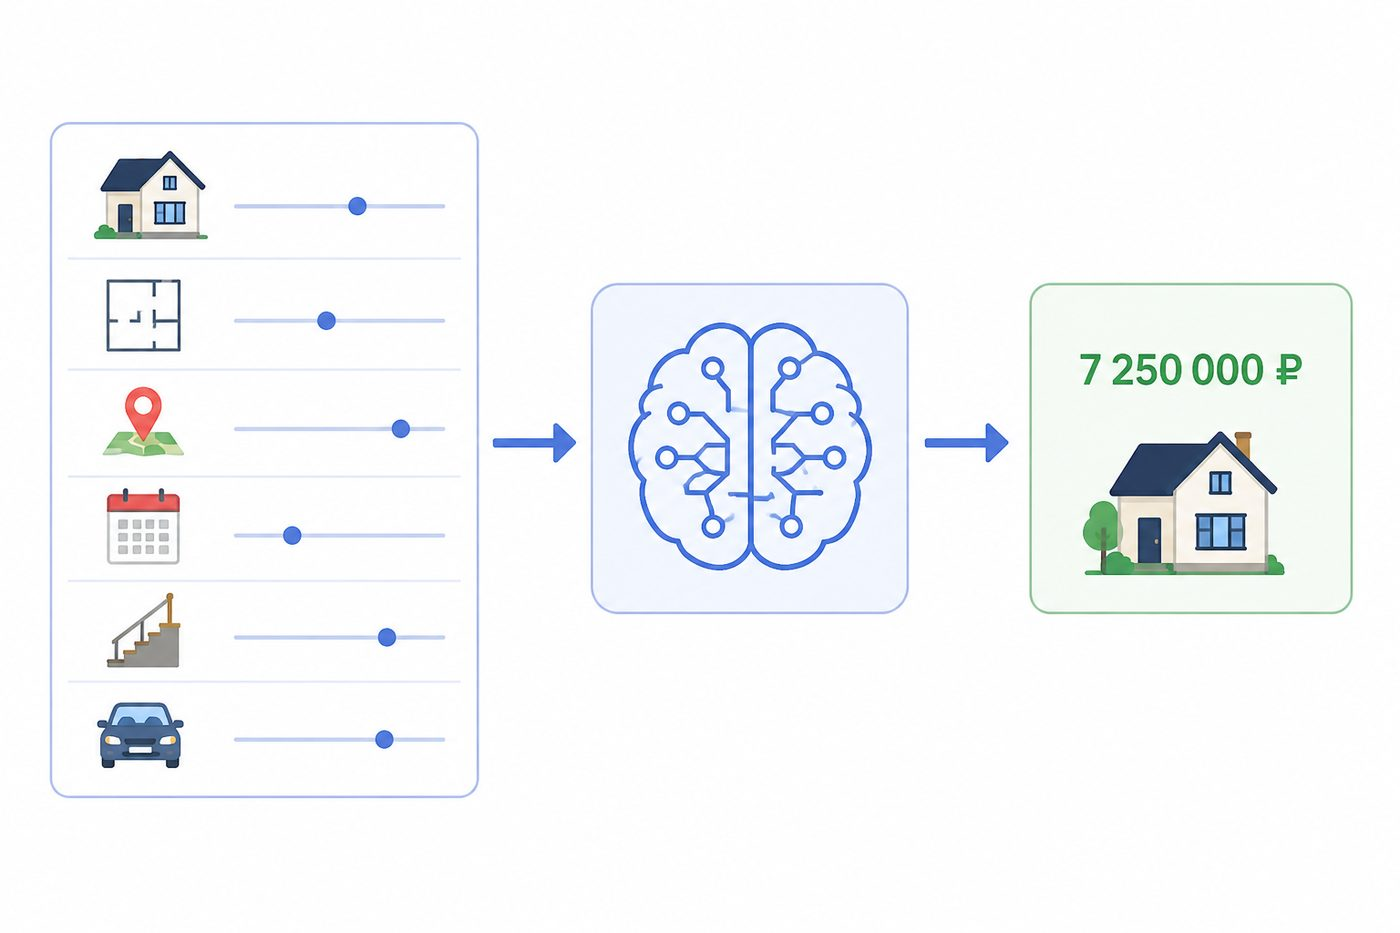

# Задача кластеризации

Ещё один распространённый тип задач машинного обучения — кластеризация.

В отличие от классификации и регрессии, **в задаче кластеризации нет целевой переменной**. Модель получает объекты и их признаки и должна самостоятельно разделить объекты на группы — кластеры.

При этом объекты внутри одного кластера должны быть похожи друг на друга, а объекты из разных кластеров — максимально различаться.


## Чем кластеризация отличается от классификации

При классификации классы заранее известны: например, мы хотим определить, вернёт клиент кредит или нет. В кластеризации заранее неизвестно ни количество групп, ни то, чем именно они будут отличаться друг от друга.

Например, можно разделить клиентов на несколько групп на основе их возраста, дохода и уровня образования. После кластеризации мы можем обнаружить группы клиентов с похожими характеристиками и уже затем попытаться понять, чем каждая группа отличается от других.

## Вывод

- **Классификация** отвечает на вопрос: *«К какому известному классу относится объект?»*
- **Кластеризация** отвечает на вопрос: *«Какие группы похожих объектов можно обнаружить в данных?»*


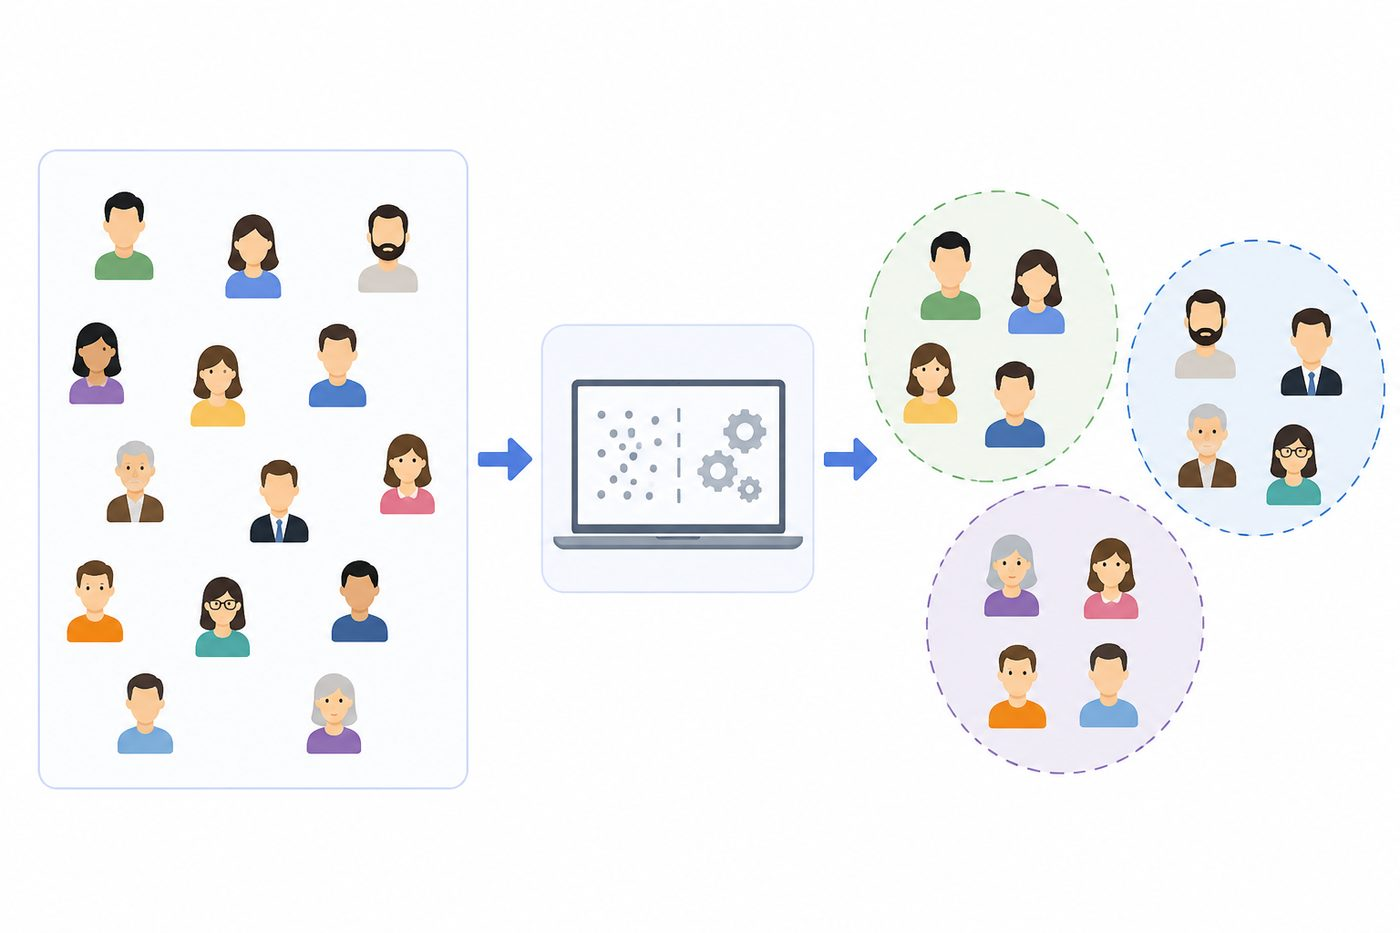

## 2. Признаки, метки и обучающая таблица

Модель ест данные в виде таблицы: строки — объекты (Sample,	样本), столбцы — **признаки** (features, 特征), плюс отдельный столбец — **метка** (label, 标签) с правильным ответом.


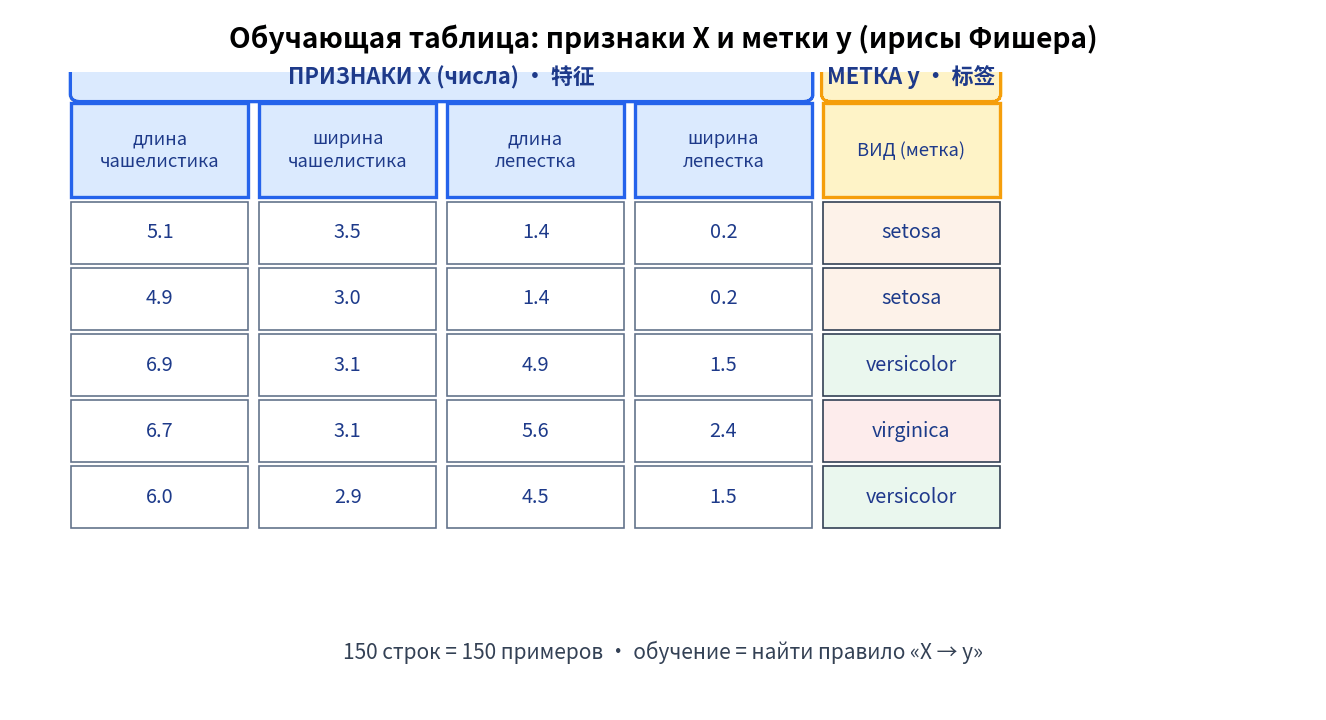

Наш главный «подопытный» на ближайшие две лекции — **ирисы Фишера**: 150 цветков трёх видов, у каждого 4 измерения. Ботаник Рональд Фишер опубликовал эти данные в 1936 году, и с тех пор это «Hello, World!» машинного обучения: таблица маленькая, наглядная, и виды почти линейно разделимы.

Три уточнения, которые часто пропускают новички:

1. **Признаки — числа** (см. лекцию 2). Если признак категориальный («город: Пекин»), его кодируют one-hot или порядковым кодом.
2. **Метки бывают разные.** Класс из списка → задача классификации; число → регрессия; нет меток → обучение без учителя.
3. **Качество данных важнее количества признаков.** 5 честных информативных признаков работают лучше 500 «мусорных» (широкие таблицы ловят ложные закономерности — эффект «проклятия размерности»).



### 🛠️ Откуда берутся признаки?

Три источника — по мере роста сложности курса:

1. **Уже есть в данных.** Цена квартиры, возраст клиента, длина лепестка — просто измерили и записали.
2. **Их придумывает инженер.** Для антиспам-фильтра никто не подаёт сырой текст: инженер вычисляет *длину письма*, *число заглавных букв*, *наличие вложений*. Это называется **конструированием признаков** — вдумчивая работа, часто решающая качество модели.
3. **Сеть извлекает сама.** В глубоком обучении (лекции 5–6) признаки придумывать не нужно: нейросеть сама учится превращать пиксели в полезные описания — от штрихов до целых объектов.


In [ ]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()
df = pd.DataFrame(iris.data, columns=["дл_чашелистика", "шир_чашелистика",
                                       "дл_лепестка", "шир_лепестка"])
df["метка (вид)"] = [iris.target_names[t] for t in iris.target]
print(df.shape, "— 150 объектов × 4 признака + метка")
df.head(8)

(150, 5) — 150 объектов × 4 признака + метка


,дл_чашелистика,шир_чашелистика,дл_лепестка,шир_лепестка,метка (вид)
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa


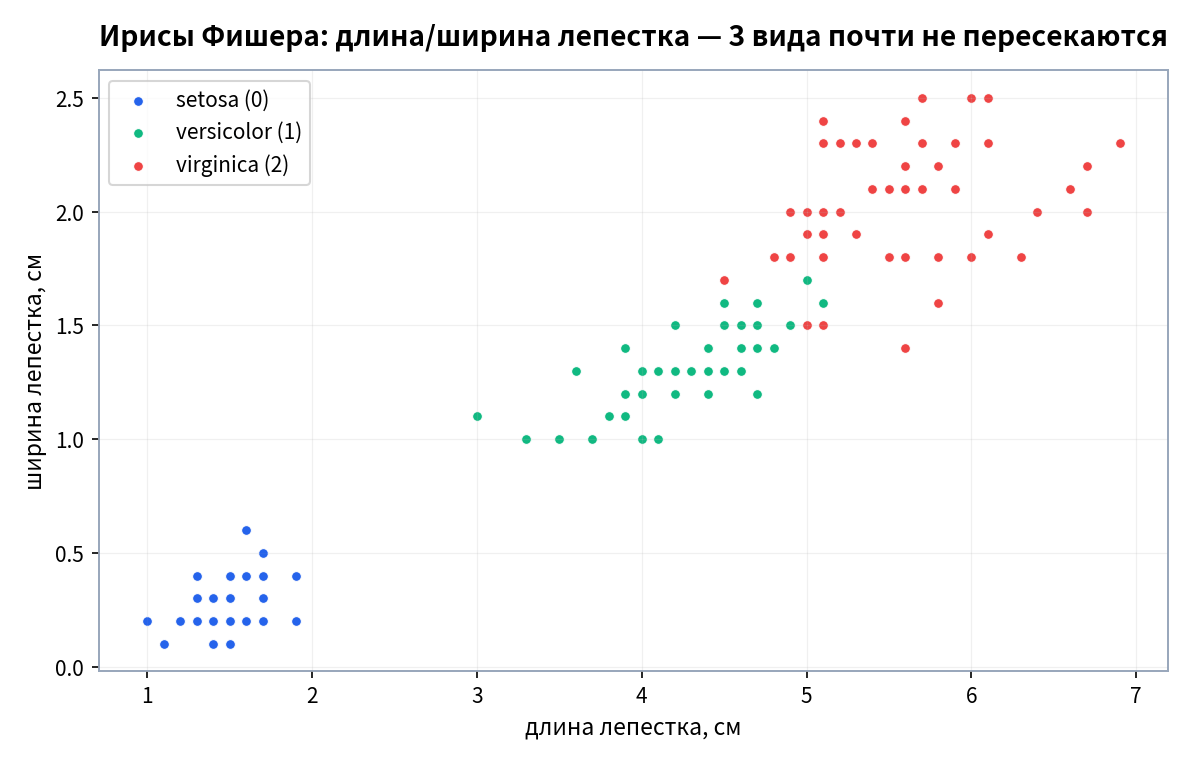

Одного взгляда на диаграмму достаточно, чтобы понять силу простых методов: **setosa** (синие точки) отделяется по длине лепестка < 2,5 см буквально одной линией; versicolor и virginica почти не пересекаются. Правило «измерь лепесток — узнай вид» модель найдёт сама.


## 3. Три типа машинного обучения

По наличию «ответов» в опыте E различают три парадигмы:


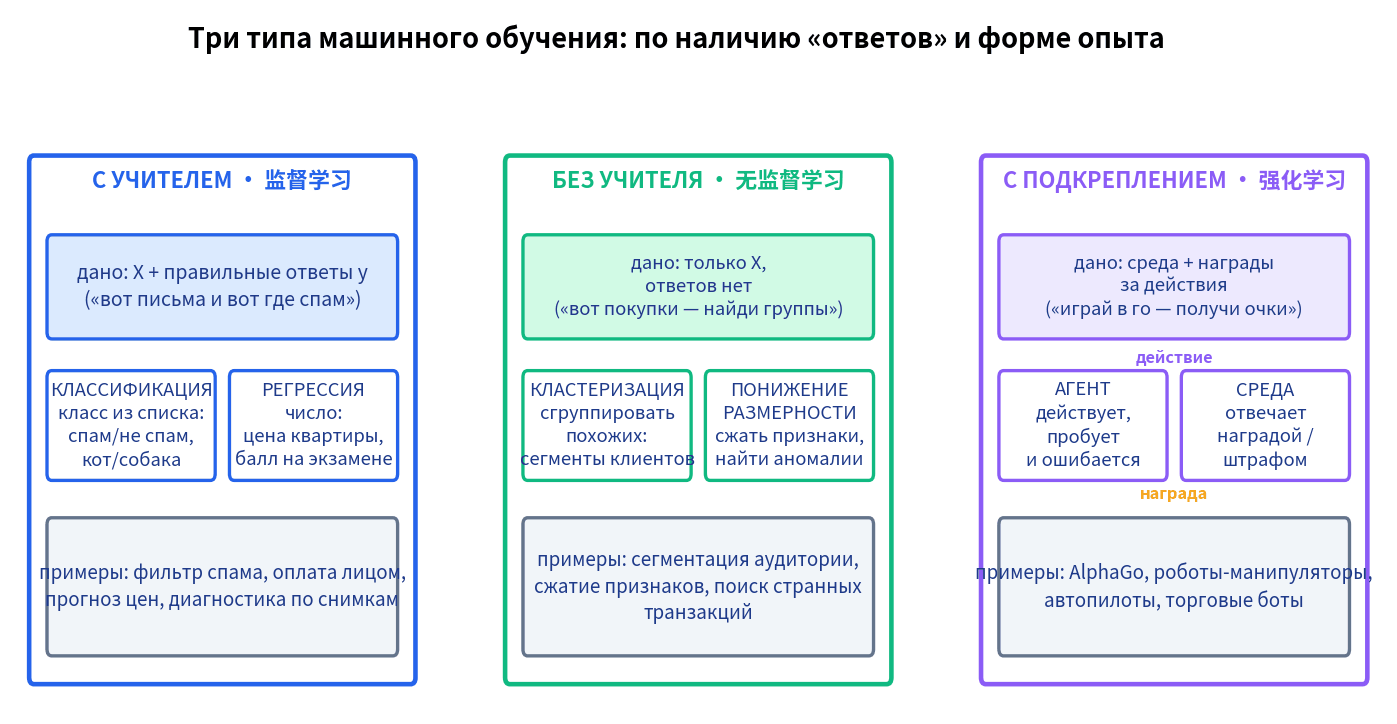

### 3.1. Обучение с учителем (supervised, 监督学习)

«Учитель» — это человек, который заранее разметил примеры: письма → спам/не спам, фото → «кот», квартиры → цены. Дано: пары $(\mathbf{x}_i, y_i)$. Найти: функцию $f: \mathbf{x} \mapsto y$.

Два подтипа различаются типом ответа $y$:


# Обучение с учителем и обучение без учителя

Задачи машинного обучения можно разделить на две большие группы в зависимости от того, есть ли в данных **известные правильные ответы**: **обучение с учителем** и **обучение без учителя**.

## Обучение с учителем

В задачах обучения с учителем для объектов известны значения целевой переменной. Модель учится находить закономерности между признаками объектов и известными ответами, чтобы затем делать предсказания для новых объектов.

К обучению с учителем относятся:
- **Классификация**;
- **Регрессия**.

## Обучение без учителя

В задачах обучения без учителя целевой переменной нет. Модель работает только с признаками объектов и самостоятельно ищет в данных закономерности или структуру.

Пример задачи без учителя:
- **Кластеризация** — разделение объектов на группы похожих объектов.


## Главное различие

- **При обучении с учителем** мы знаем правильные ответы и учимся их предсказывать.
- **При обучении без учителя** правильных ответов нет — модель самостоятельно ищет структуру в данных.


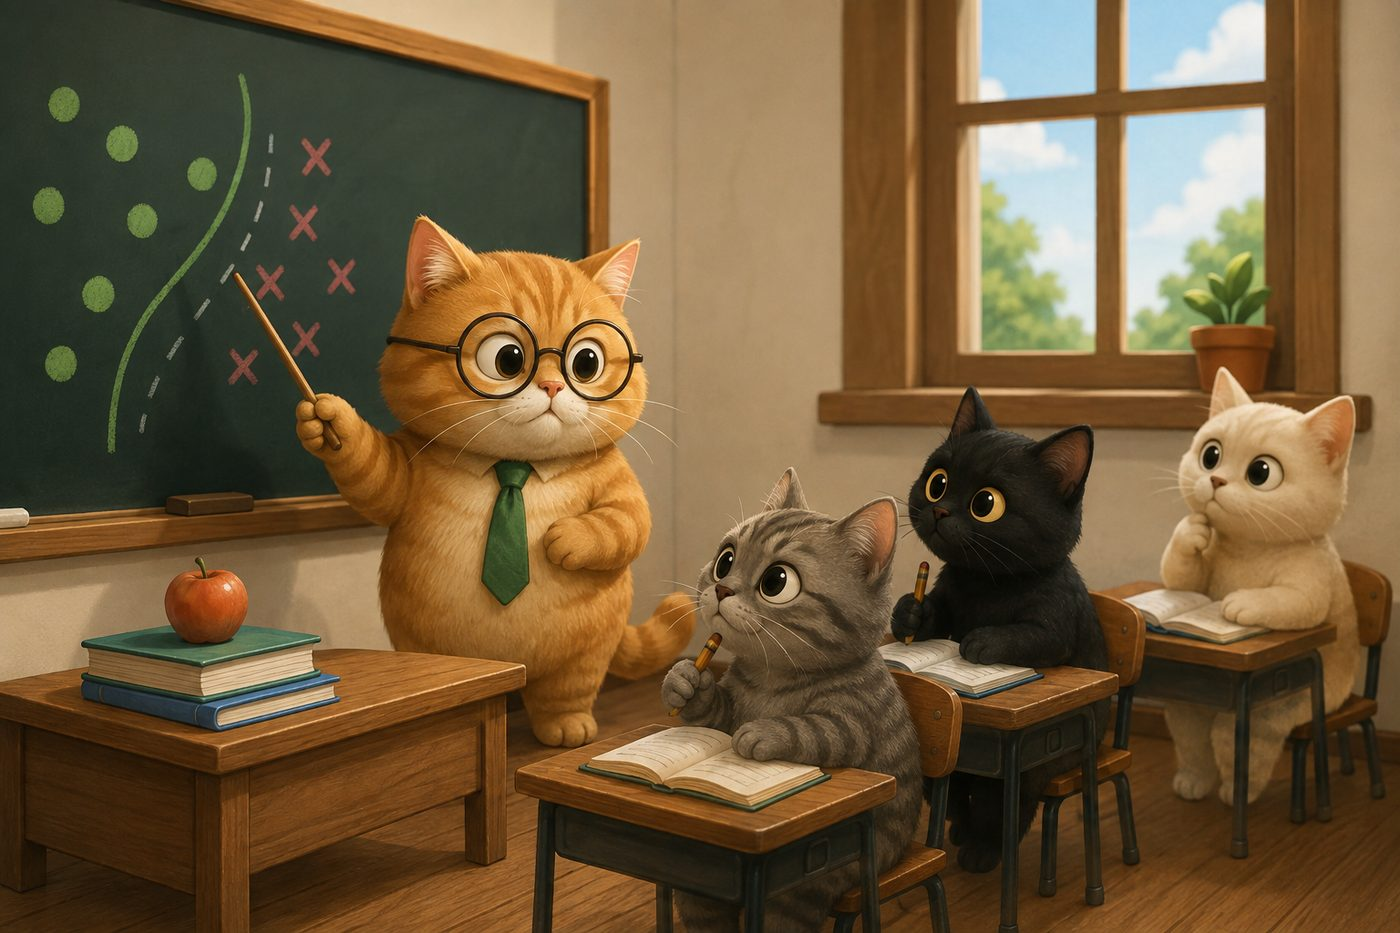

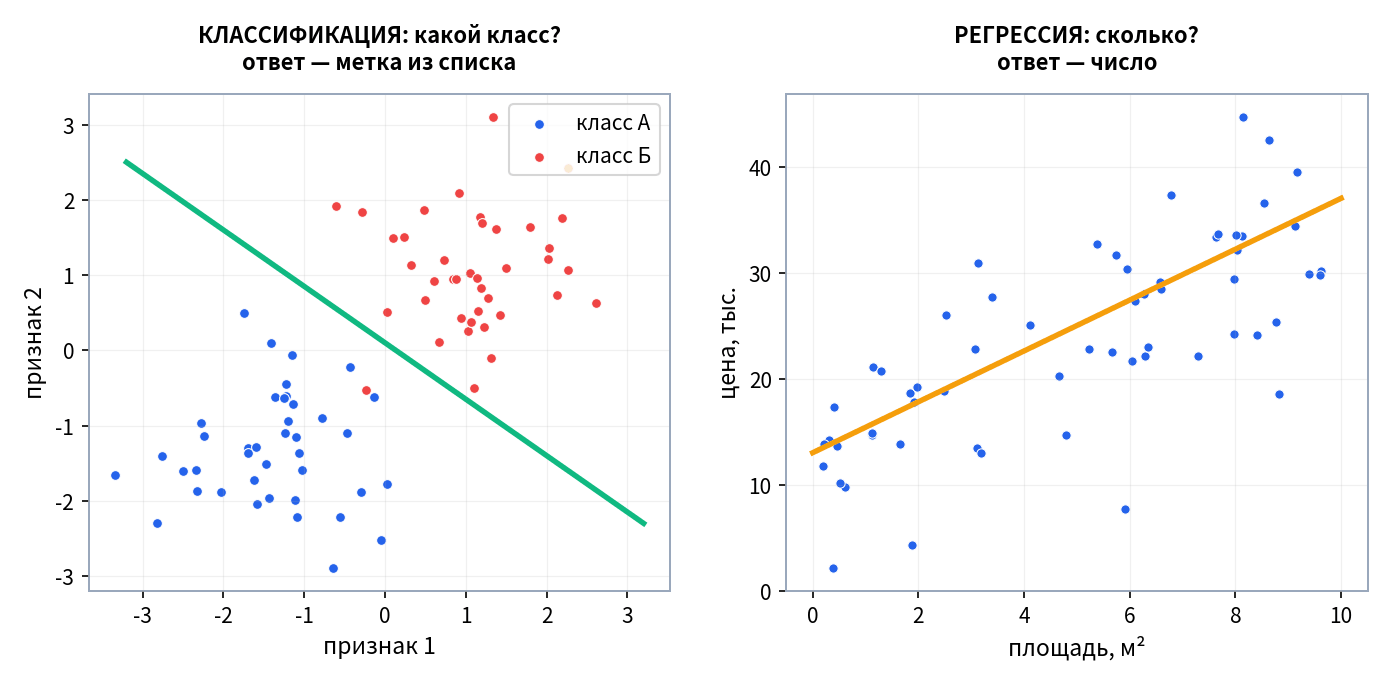

| | Классификация 分类 | Регрессия 回归 |
|---|---|---|
| Ответ | метка из конечного списка | непрерывное число |
| Примеры | спам/не спам; ирисы; болезнь есть/нет | цена квартиры; спрос на завтра; балл студента |
| Метрики (лекция 4) | accuracy, precision, recall | MAE, RMSE, R² |
| Модели | kNN, логистическая регрессия, деревья, CNN | линейная регрессия, деревья, градиентный бустинг |

### 3.2. Обучение без учителя (unsupervised, 无监督学习)

Ответов нет — только признаки. Система сама находит структуру: **кластеризацию** (группы похожих клиентов для рассылок), **понижение размерности** (сжатие 100 признаков в 10 для визуализации), **поиск аномалий** (странная банковская транзакция). Качество оценить сложнее — «правильных групп» никто не знает; часто меряют компактность кластеров или смотрят глазами.

### 3.3. Обучение с подкреплением (reinforcement, 强化学习)

Агент действует в среде, получает награду или штраф, и учит стратегию, максимизирующую суммарную награду. Так учились AlphaGo (награда — победа в партии) и роботы-манипуляторы. Этот тип за рамками практических работ курса, но идея — мостик к лекции 7: дообучение LLM на предпочтениях людей устроено похоже (награда = «ответ понравился»).

**❓ Быстрая классификация задач** (назовите тип): (а) разложить новости по темам без списка тем; (б) предсказать пробку через час; (в) научить квадрокоптер посадке; (г) отличить каску на фото рабочего. *(Ответы: а — без учителя, кластеризация; б — с учителем, регрессия; в — с подкреплением; г — с учителем, классификация.)*


# И это ещё не всё!

На практике задач машинного обучения гораздо больше, чем классификация, регрессия и кластеризация.

## Обучение с учителем (supervised learning)

К этому типу относятся задачи, где у данных есть известные правильные ответы:

- классификация;
- регрессия;
- ранжирование;
- рекомендательные системы.

## Обучение без учителя (unsupervised learning)

Здесь правильных ответов нет — модель сама ищет закономерности в данных:

- кластеризация;
- снижение размерности;
- поиск аномалий;
- генерация изображений, текстов и других данных;
- рекомендательные системы*.

> *Рекомендательные системы могут относиться как к supervised learning, так и к unsupervised learning — это зависит от используемого алгоритма.*

![Обзор типов задач ML](https://ucarecdn.stepik.net/dbea9475-a83f-4afd-9851-28b11942f078/)

## Отдельный


## 4. Обучение и проверка: обучающая и тестовая выборки (训练集与测试集): «нельзя проверять на учебнике»

Ключевой вопрос машинного обучения: **умеет ли модель обобщать** — верно отвечать на данных, которых не видела? Экзаменационная логика:

Одна из главных ошибок новичков — проверять модель на тех же данных, на которых она училась. Это как дать студенту на экзамене те же самые вопросы, что были в домашнем задании. Студент получит 100%, но мы не узнаем, понял ли он тему или просто запомнил ответы.

- **Обучающая выборка (Training Set, 训练集):** Данные, на которых модель учится (находит закономерности). Обычно 70–80% всех данных.
- **Тестовая выборка (Test Set, 测试集):** Данные, которые модель **никогда не видела**. На них мы проверяем, насколько хорошо модель умеет обобщать (работать с новыми примерами). Обычно 20–30%.

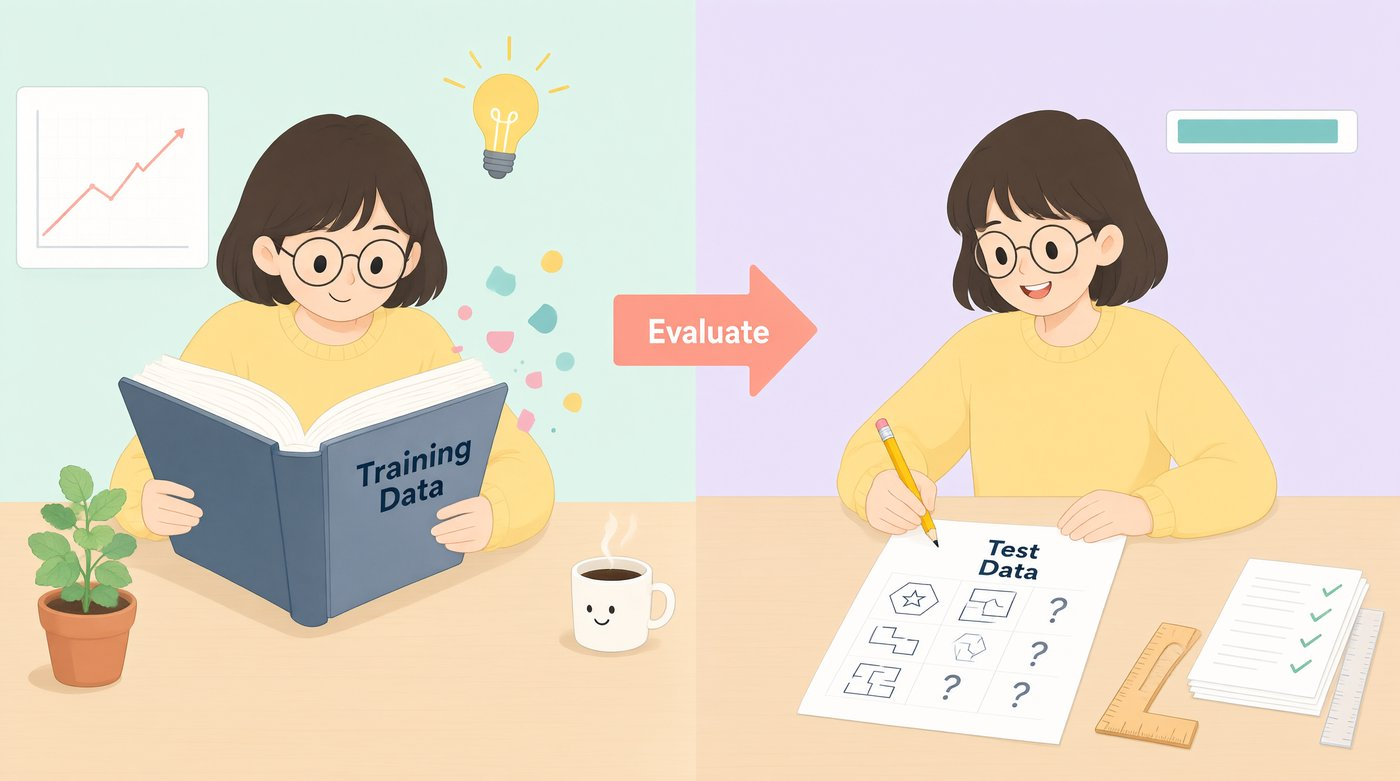
*Рис. 2. Метафора: студент учится по учебнику (обучающая выборка), а затем сдаёт экзамен с новыми вопросами (тестовая выборка).*

> ⚠️ **Переобучение (Overfitting, 过拟合):** Если модель показывает 100% точности на обучающих данных, но плохо работает на тестовых, значит, она просто "зазубрила" примеры, как стихи, но не поняла правила.

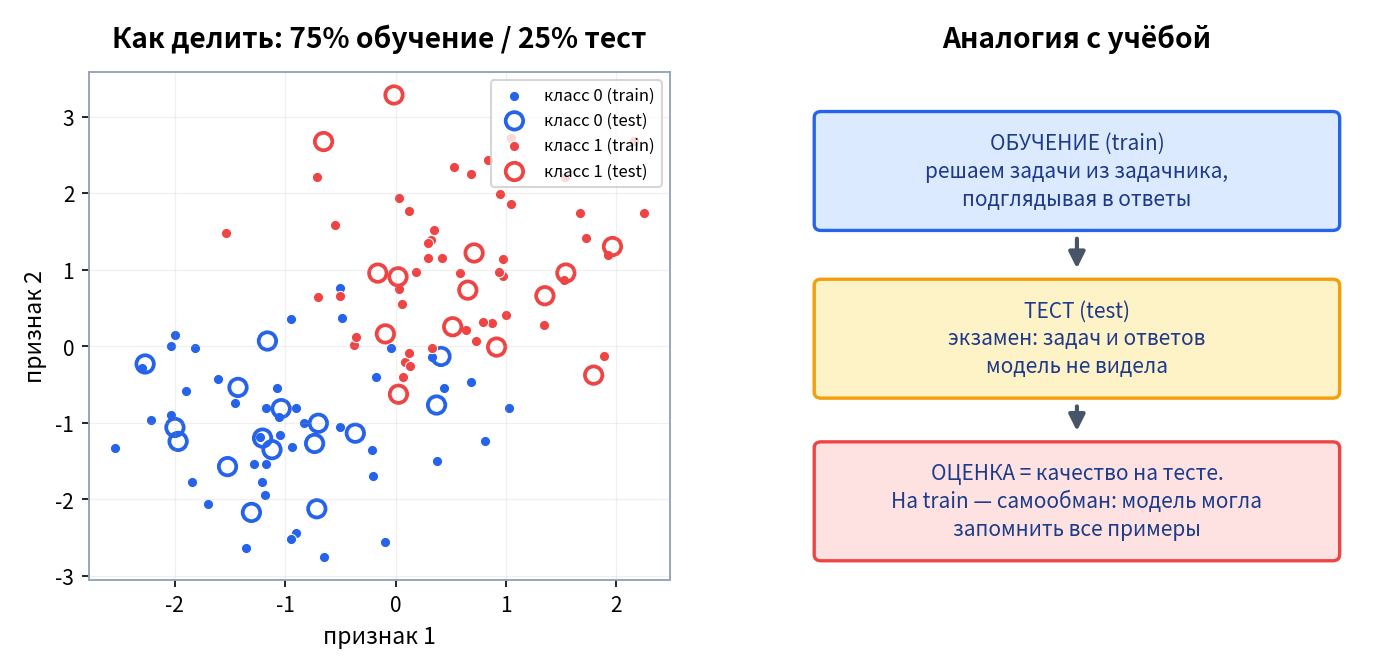

Стандарт: **75% на обучение, 25% на тест** (бывают 80/20, 70/30). В scikit-learn:

```python
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
```

- `random_state` — фиксирует «перемешивание», чтобы результат повторялся.
- `stratify=y` — следит, чтобы доля классов в train и test совпала с исходной (для ирисов: по 12–13 цветков каждого вида в тесте, а не «повезло/не повезло»).

In [ ]:
# Демонстрация разделения данных на обучающую и тестовую выборки
import pandas as pd
from sklearn.model_selection import train_test_split

data = {
    'hours': [10, 2, 8, 1, 6, 3, 9, 4, 7, 5],
    'attendance': [90, 40, 80, 30, 70, 50, 85, 60, 75, 65],
    'passed': [1, 0, 1, 0, 1, 0, 1, 0, 1, 1]
}
df = pd.DataFrame(data)

X = df[['hours', 'attendance']]  # Признаки (特征)
y = df['passed']                  # Метка (标签) - правильный ответ

# Делим данные: 80% на обучение, 20% на тест
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("📚 Обучающая выборка (模型学习的数据):")
print(X_train)
print("\n📝 Тестовая выборка (模型未见过的数据, 用于考试):")
print(X_test)

📚 Обучающая выборка (模型学习的数据):
   hours  attendance
5      3          50
0     10          90
7      4          60
2      8          80
9      5          65
4      6          70
3      1          30
6      9          85

📝 Тестовая выборка (模型未见过的数据, 用于考试):
   hours  attendance
8      7          75
1      2          40


### 4.1. Утечка данных — источник «чудесных» моделей

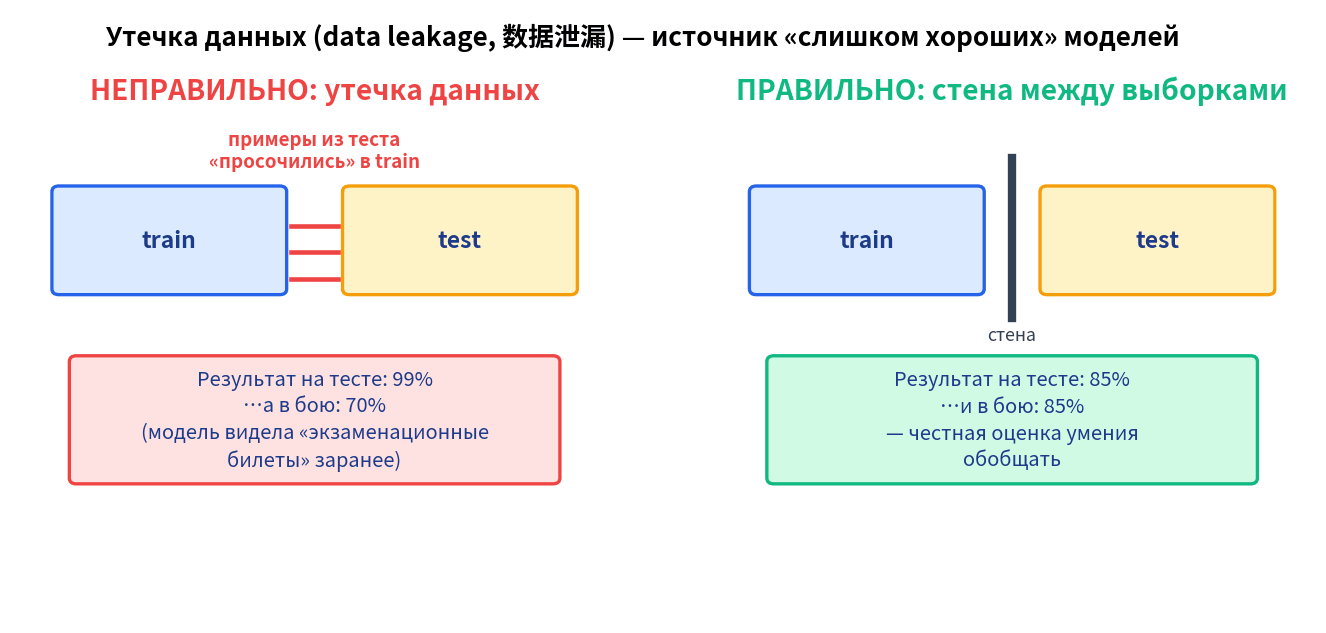

**Утечка (data leakage, 数据泄漏)** — любая информация из теста (или из будущего), которая попала в процесс обучения. Классические сюжеты:

1. «случайно» смешали train и test до деления;
2. признак, который «подглядывает» в будущее: предсказываем дефолт клиента, а среди признаков — «сумма взысканных долгов» (она появляется только после дефолта);
3. нормализация по всей выборке до деления: средние и разброс «знают» тест.

Симптом всегда один: на тесте 99%, в бою — 70%. **Лечится дисциплиной:** все статистики считаются только по train; тест открывается один раз — в конце.

### 4.2. Почему тест тоже нельзя «пощупать» много раз

Если выбирать модель по десяткам прогонов на одном тесте, вы неявно подстраиваетесь под его конкретные примеры. Для честного выбора гиперпараметров используют **кросс-валидацию** — деление train на 5 «складок» по кругу (подробно в лекции 4). Тест остаётся «замком на последней двери».



### 4.3. Тройное деление: валидация — «репетиция экзамена»

В реальных проектах выборку делят на **три** части:

| Выборка | Доля | Роль |
|---|---|---|
| Обучающая | ~70 % | по ней модель учится |
| **Валидационная** | ~15 % | «репетиция экзамена»: на ней подбирают гиперпараметры (то самое $k$ у соседей, глубину дерева) и сравнивают модели-кандидаты |
| Тестовая | ~15 % | вскрывается **строго один раз** в самом конце, как настоящий экзамен |

Почему тест охраняют так строго? Каждое решение, принятое по тесту, незаметно «подтачивает» его честность: выбирая лучшую из двадцати моделей по тесту, мы невольно выбираем и удачу, а не качество. **Правило простое: чем чаще вы смотрите на тест, тем меньше ему можно верить.**


In [ ]:
from sklearn.model_selection import train_test_split

X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print("Обучение:", X_train.shape, "| Тест:", X_test.shape)
print("В тесте по видам:", [int((y_test == k).sum()) for k in range(3)],
      "— stratify выровнял классы")

Обучение: (112, 4) | Тест: (38, 4)
В тесте по видам: [12, 13, 13] — stratify выровнял классы


---
## 🎬 Видеоматериалы: типы ML и выборки
Видео к разделам 1–4: понятия ML, типы обучения, обучающая и тестовая выборки.
### 🇷🇺 РУС · русскоязычные видео (3)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [ML #1. Что такое машинное обучение? Обучающая выборка и признаки](https://rutube.ru/video/d50834240450f7eee51b36212f431e99/) | Rutube · SelfEdu | 12 мин | Л3 §2: признаки, метки, обучающая таблица  X |
| 2 | [ML #2. Постановка задачи машинного обучения](https://rutube.ru/video/44d371973016ed28ce19be8b6a20659f/) | Rutube · SelfEdu | 12 мин | Л3 §3: обучение с учителем и без  X |
| 3 | [ML #4. Способы оценивания степени переобучения моделей](https://rutube.ru/video/6745db93991858e3ab0f20fdd717f4ef/) | Rutube · SelfEdu | 7 мин | Л3 §5: недо- и переобучение  X |
### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (3)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Выбор модели: обучающая и проверочная выборки](https://www.bilibili.com/video/BV1EY6FBwE8P?p=37)<br>· ориг.: *37.1-模型选择* | Bilibili · 李沐 | 18 мин | Л3 §4: «нельзя проверять на учебнике»  ✓ |
| 2 | [Переобучение и недообучение](https://www.bilibili.com/video/BV1EY6FBwE8P?p=38)<br>· ориг.: *38.2-过拟合和欠拟合* | Bilibili · 李沐 | 16 мин | Л3 §5: диагностика по кривым обучения  ✓ |
| 3 | [Переобучение и недообучение](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=29)<br>· ориг.: *6-1 过拟合与欠拟合* | Bilibili · 清华AI | 18 мин | Л3 §5: диагностика пере/недообучения  ✓ |
### 🇬🇧 EN · англоязычные видео (4)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [StatQuest: главные идеи машинного обучения](https://www.bilibili.com/video/BV1xr421x7xw/)<br>· ориг.: *【官方双语】机器学习新手必看，超简洁入门视频，带你理解机器学习核心* | Bilibili · StatQuest | 12 мин | Л3 §1: что значит «учиться» — ядро ML без формул  ✓ |
| 2 | [StatQuest: что такое переобучение (bias и variance)](https://www.bilibili.com/video/BV1s1421C7TR/)<br>· ориг.: *【官方双语】如何理解模型过拟合？理解模型的偏差&方差* | Bilibili · StatQuest | 6 мин | Л3 §5: обучение ≠ запоминание  ✓ |
| 3 | [Andrew Ng: Обучение с учителем](https://www.bilibili.com/video/BV1owrpYKEtP?p=3)<br>· ориг.: *3.监督学习部分 (речь — английская)* | Bilibili · 吴恩达 | 14 мин | Л3 §3.1: регрессия и классификация  ✓ |
| 4 | [Andrew Ng: Обучение без учителя](https://www.bilibili.com/video/BV1owrpYKEtP?p=4)<br>· ориг.: *4.无监督学习部分 (речь — английская)* | Bilibili · 吴恩达 | 12 мин | Л3 §3.2: кластеризация  ✓ |

> 📄 Полная версия с идентичными ссылками: PDF «Видеоматериалы по 5 модулям и 10 лекциям», глава соответствующего модуля.

## 5. Обучение ≠ запоминание: недо- и переобучение

Пока модель учится на train, ошибка падает почти всегда. Вопрос — что происходит на тесте. Три сценария:


### Что такое переобучение (过拟合)?
Это как **зубрёжка (死记硬背)** перед экзаменом. Студент заучивает ответы на конкретные вопросы из билета (низкая ошибка на обучении), но проваливается на экзамене, если вопросы чуть-чуть изменятся (высокая ошибка на тесте).

### Как распознать?
- Точность на обучении (Train) растёт и приближается к 100%.
- Точность на тесте (Test) перестаёт расти и начинает **падать**.

### Как бороться?
1. Собрать **больше данных**.
2. Использовать **более простую модель** (уменьшить глубину дерева, количество нейронов).
3. Применить **регуляризацию** (штрафовать модель за излишнюю сложность) или **Dropout** (случайно «выключать» часть нейронов).
4. **Ранняя остановка (Early Stopping):** прекратить обучение, когда ошибка на тесте начинает расти.



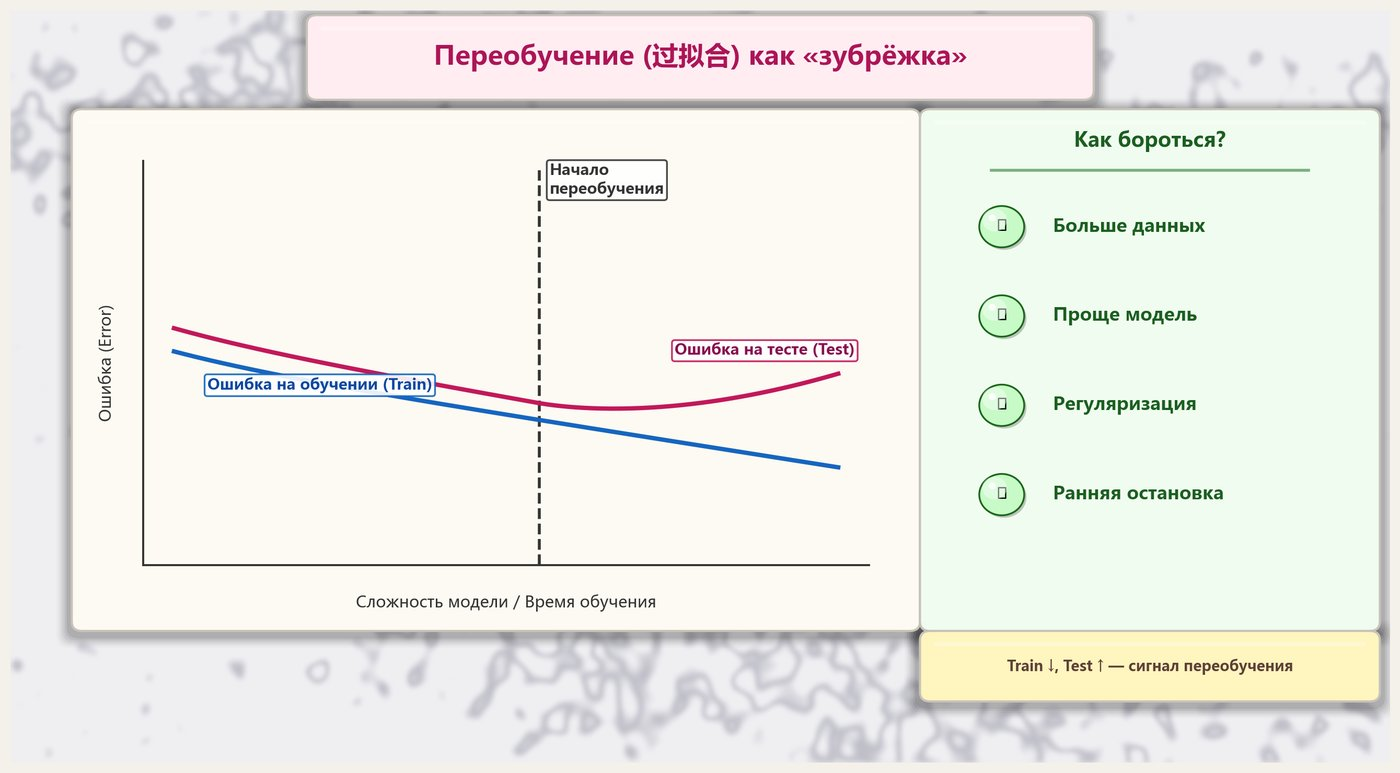

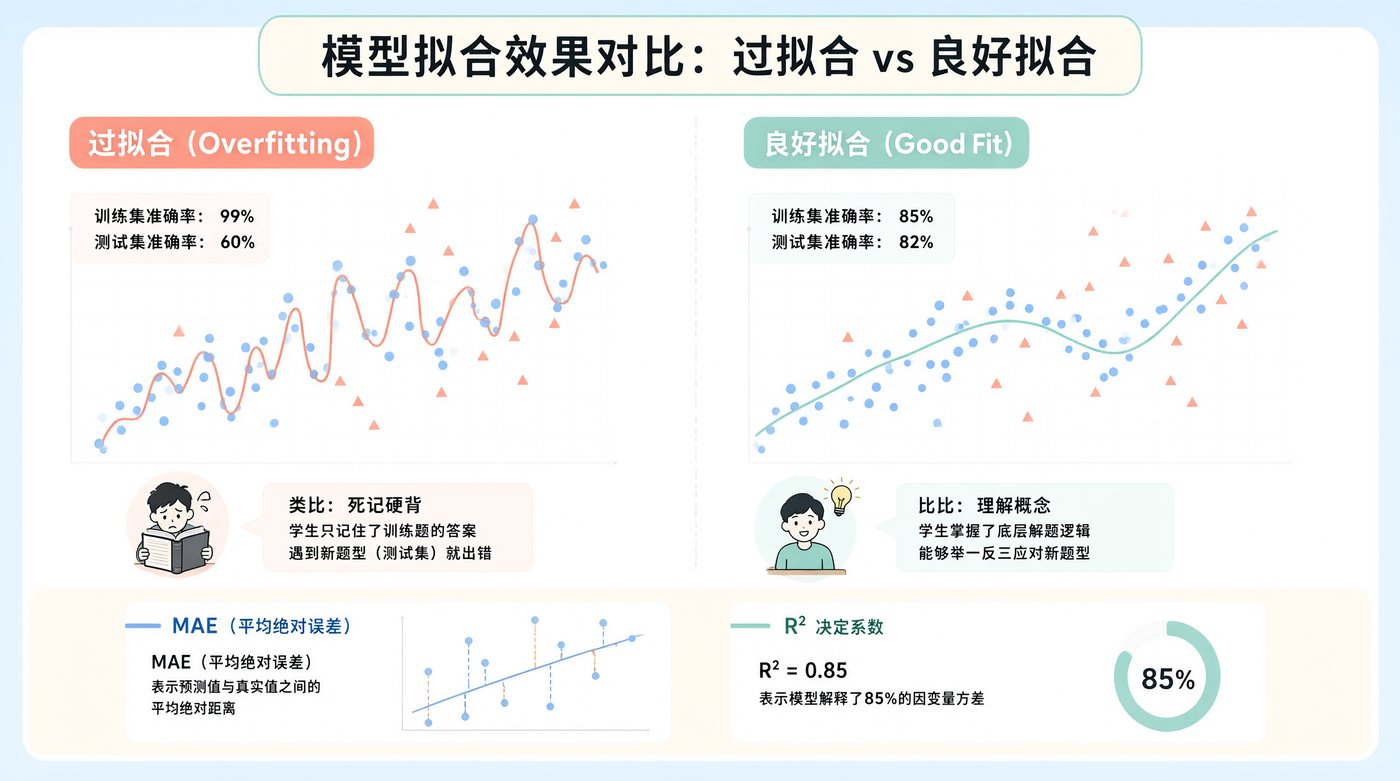

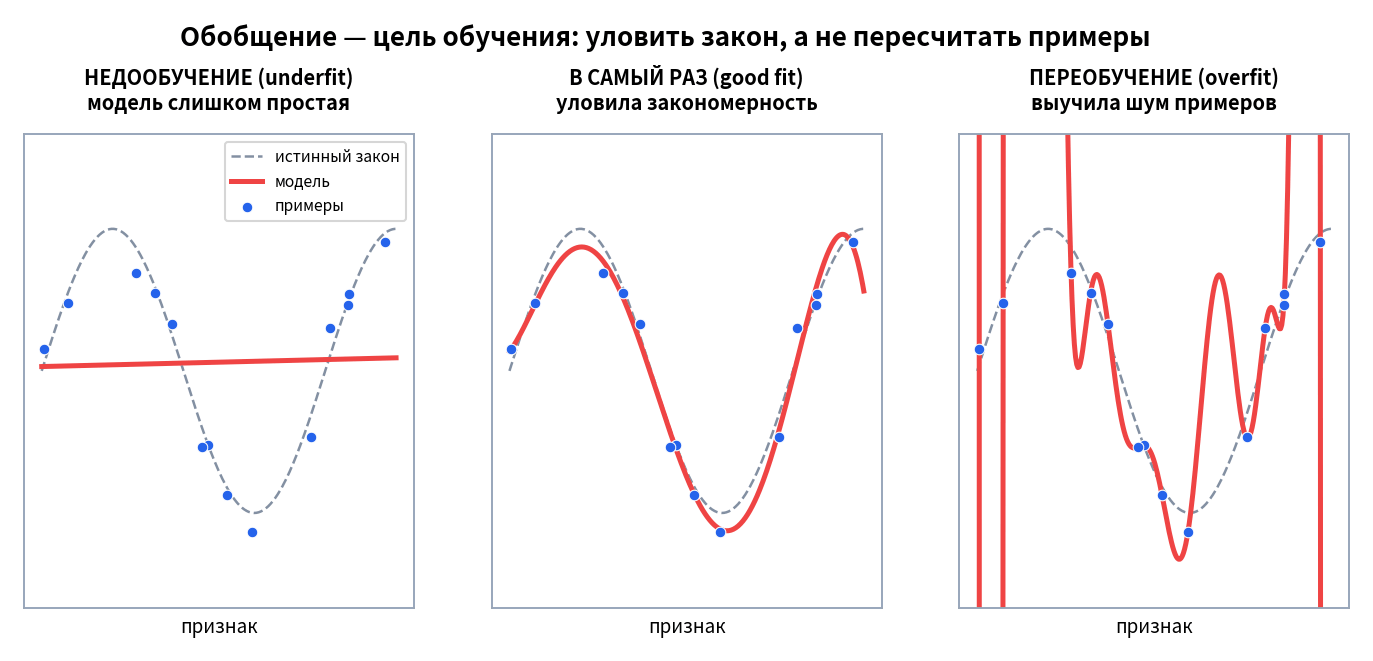

- **Недообучение (underfit, 欠拟合):** модель слишком проста — прямая линия не может описать волну. Плохо и на train, и на тесте.
- **В самый раз:** уловила закономерность, лежащую за примерами, — на тесте тоже хороша.
- **Переобучение (overfit, 过拟合):** модель слишком гибкая и «выучила наизусть» примеры вместе с шумом: на train ошибка ~0, на тесте — провал. Как студент, зазубривший ответы задачника, но не понявший метода: на экзамене с новыми задачами — двойка.

Симптом переобучения — **расходящиеся кривые ошибок** train/test. Лечение: больше данных, более простая модель, регуляризация, ранняя остановка (лекции 5–6). Сейчас важно распознавать сценарии глазами.


## 6. Каркас scikit-learn и полный цикл проекта

### 6.1. Четыре строчки, которые знают все

**Scikit-learn (sklearn)** — это «набор готовых моделей» ( готовый инструментарий). Неважно, какой алгоритм вы выберете (дерево, линейная регрессия или kNN), код всегда выглядит одинаково.

### 🔄 4 шага работы с любой моделью:
1. **Создать модель** (Импортировать класс и создать объект).
2. **Обучить** (`fit`): передать признаки (X) и ответы (y).
3. **Спрогнозировать** (`predict`): передать новые признаки (X_test).
4. **Оценить** (`score` или метрики): сравнить прогноз с реальными ответами (y_test).

Вся библиотека построена вокруг единого интерфейса:



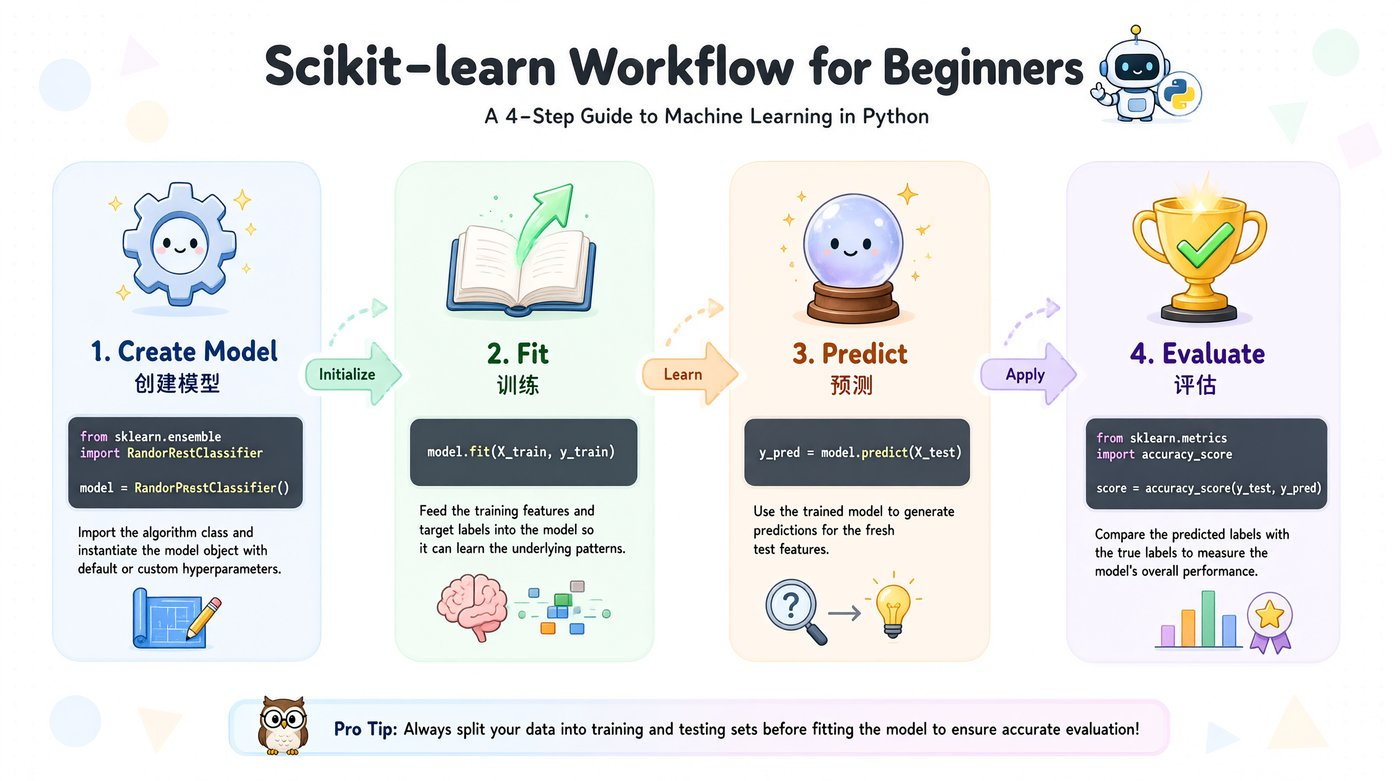
*Рис. 1. Единый шаблон работы в Scikit-learn: 4 шага от создания модели до оценки.*

> 💡 **Аналогия:** Это как использование микроволновки. 1. Выбрать режим (создать). 2. Положить еду и нажать старт (fit). 3. Достать готовую еду (predict). 4. Попробовать на вкус (оценить).

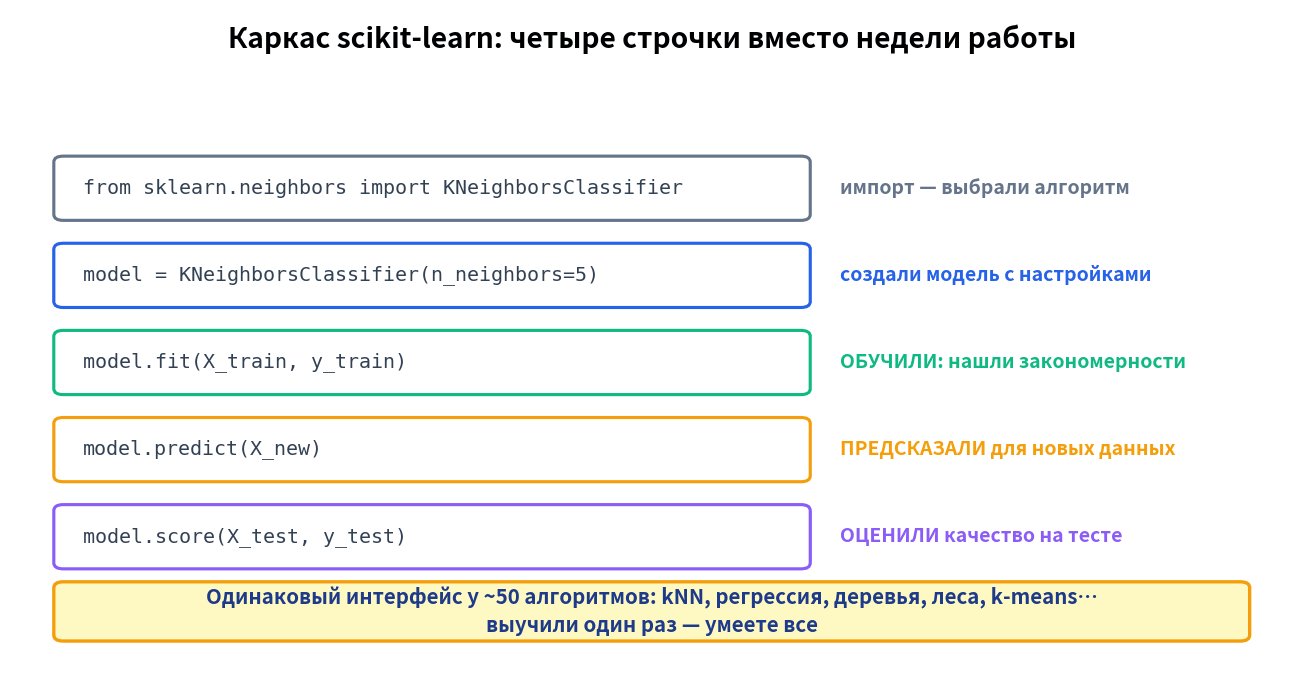


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

models = {
    "KNN (соседи)":         KNeighborsClassifier(n_neighbors=5),
    "Логистическая регр.":  LogisticRegression(max_iter=1000),
    "Дерево решений":       DecisionTreeClassifier(max_depth=3),
}
for name, m in models.items():
    m.fit(X_train, y_train)                    # учимся на обучающей части
    print(f"{name:22s} точность на тесте: {m.score(X_test, y_test):.2%}")

KNN (соседи)           точность на тесте: 97.37%
Логистическая регр.    точность на тесте: 94.74%
Дерево решений         точность на тесте: 92.11%


In [ ]:
# Демонстрация 4 шагов на простом примере
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Исходные данные (Признаки: часы учёбы, посещаемость; Метка: сдал экзамен)
X_train = [[10, 90], [2, 40], [8, 80], [1, 30], [6, 70]]
y_train = [1, 0, 1, 0, 1]  # 1 = сдал, 0 = не сдал
X_test = [[9, 85], [3, 50]]
y_test = [1, 0]

# ШАГ 1: Создать модель (Создаём объект)
model = DecisionTreeClassifier(random_state=42)

# ШАГ 2: Обучить модель (fit)
model.fit(X_train, y_train)

# ШАГ 3: Спрогнозировать (predict)
predictions = model.predict(X_test)

# ШАГ 4: Оценить (evaluate)
accuracy = accuracy_score(y_test, predictions)

print(f"🤖 Предсказания: {predictions}")
print(f"✅ Реальные ответы: {y_test}")
print(f"🎯 Точность (Accuracy): {accuracy:.0%}")

🤖 Предсказания: [1 0]
✅ Реальные ответы: [1, 0]
🎯 Точность (Accuracy): 100%


Три алгоритма с разной математикой — и одинаковые четыре строчки работы. Алгоритмы этих трёх семейств мы детально разберём в лекции 4; здесь важен сам ритм: **создать → fit → predict → score**.

### 6.2. Где тратится время на самом деле


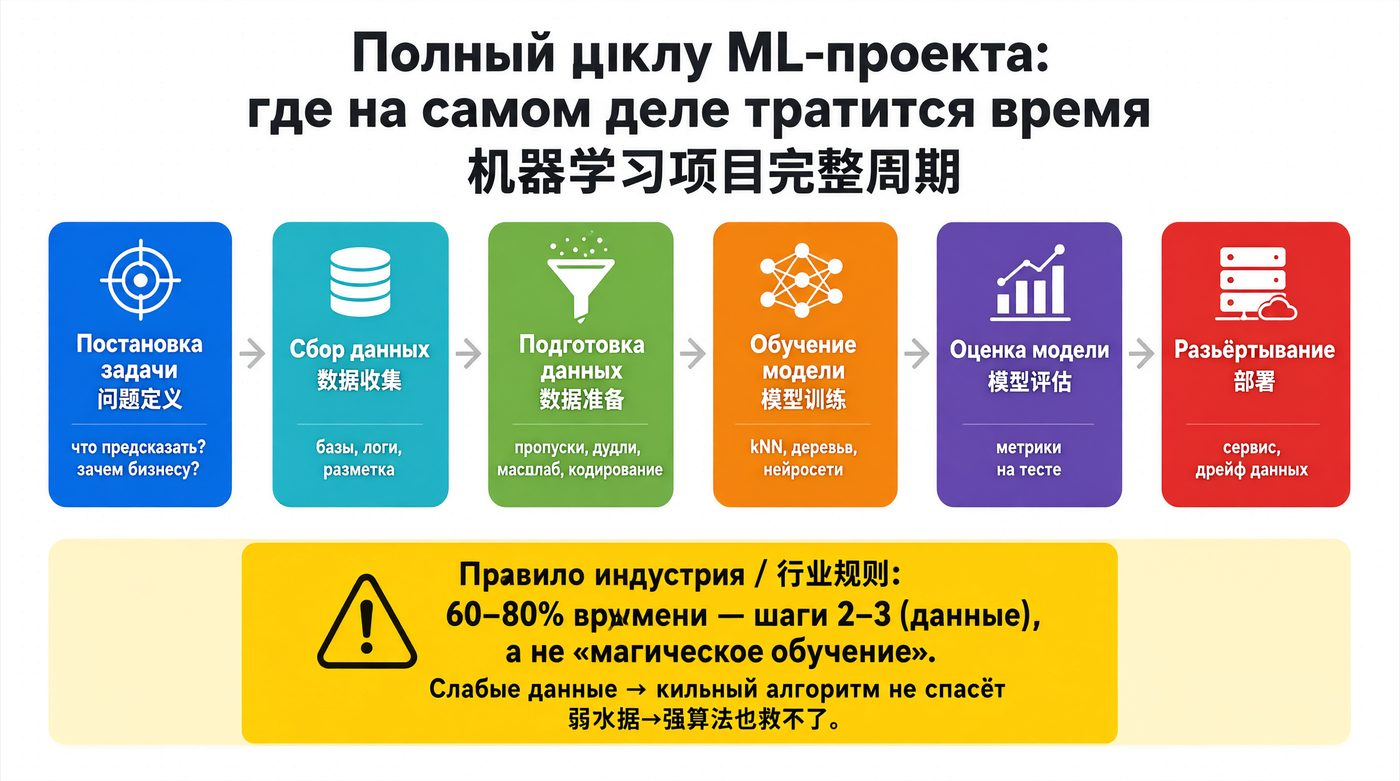

Обратите внимание на пропорции: сбор и очистка данных — 60–80% времени. «Гламурная» часть (обучение моделей) — меньше пятой. Отсюда практический вывод для курсового проекта: **начинайте собирать и чистить данные в первый день**, а не за неделю до сдачи.


## 6.3. Подготовка данных: «Мусор на входе — мусор на выходе» (25–45 мин)

Китайская пословица: 垃圾进，垃圾出 (Garbage in, garbage out). Даже самая умная модель выдаст ерунду, если данные плохие.

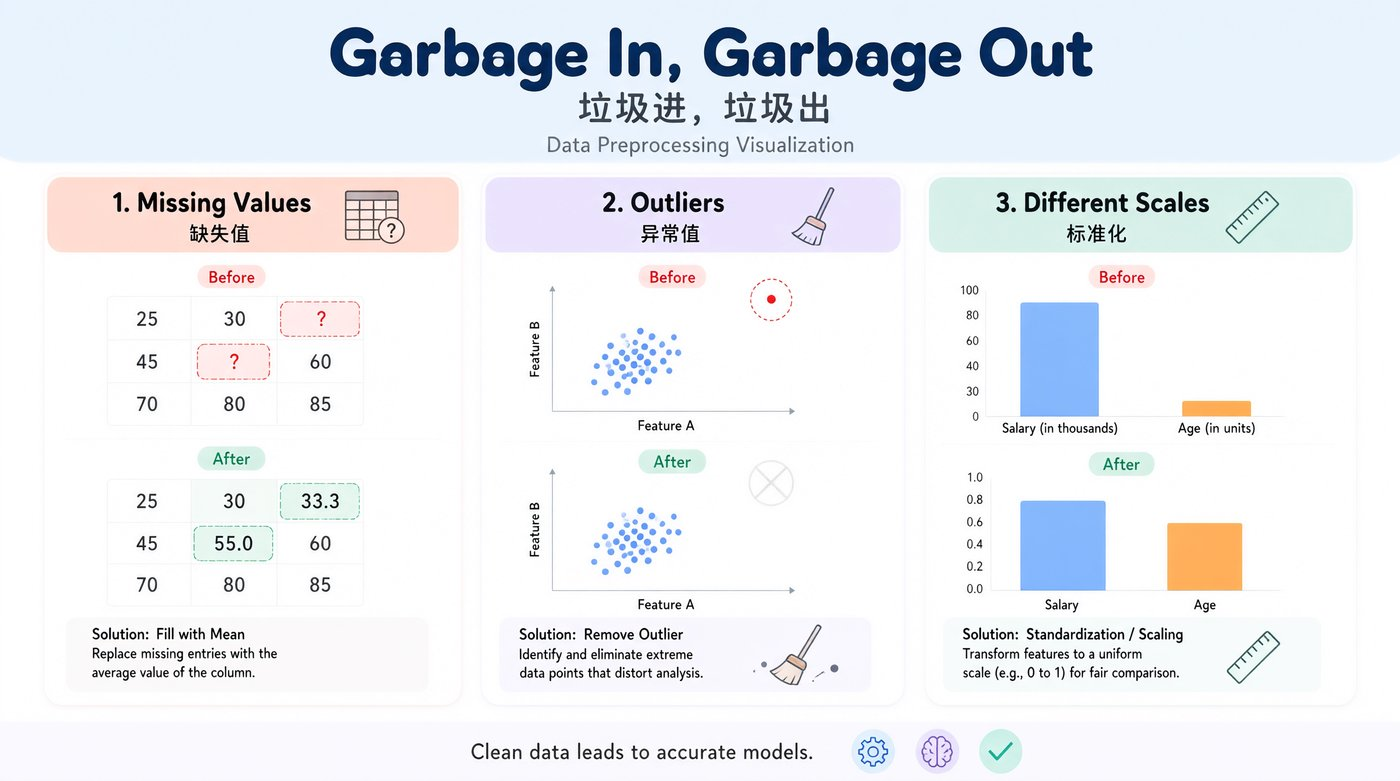
*Рис. 2. Три главные проблемы данных и их решения: пропуски, выбросы, разный масштаб.*

### 🧹 Три главные проблемы данных:
1. **Пропуски (缺失值):** Пустые ячейки в таблице.  
   *Решение:* Удалить строку ИЛИ заполнить средним значением (mean) или медианой.
2. **Выбросы (异常值):** Подозрительно большие или маленькие значения (например, возраст человека = 250 лет).  
   *Решение:* Проверить ошибку ввода или удалить аномалию.
3. **Разный масштаб (量纲不同):** Один признак измеряется в тысячах (зарплата), другой в единицах (возраст). Модель подумает, что зарплата «важнее», просто потому что числа больше.  
   *Решение:* **Масштабирование (Scaling)**. **StandardScaler** Привести все числа к одной шкале (например, от -1 до 1).

> ⚠️ **Важно:** Масштабирование нужно делать *после* разделения на обучающую и тестовую выборки, чтобы информация из теста «не подглядывала» в обучение!

In [ ]:
# Демонстрация обработки пропусков и масштабирования
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Данные с пропуском (np.nan) и разным масштабом
X_dirty = np.array([
    [10.0, 20000],  # Нормально
    [np.nan, 21000], # Пропуск в первом признаке
    [12.0, 19000]   # Нормально
])

print("📊 Исходные 'грязные' данные:\n", X_dirty)

# 1. Заполняем пропуски средним значением
imputer = SimpleImputer(strategy='mean')
X_filled = imputer.fit_transform(X_dirty)
print("\n🧹 После заполнения пропусков (средним):\n", np.round(X_filled, 1))

# 2. Масштабируем данные (приводим к среднему 0 и стандартному отклонению 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filled)
print("\n️ После масштабирования (StandardScaler):\n", np.round(X_scaled, 2))

📊 Исходные 'грязные' данные:
 [[1.0e+01 2.0e+04]
 [    nan 2.1e+04]
 [1.2e+01 1.9e+04]]

🧹 После заполнения пропусков (средним):
 [[1.0e+01 2.0e+04]
 [1.1e+01 2.1e+04]
 [1.2e+01 1.9e+04]]

️ После масштабирования (StandardScaler):
 [[-1.22  0.  ]
 [ 0.    1.22]
 [ 1.22 -1.22]]


---
## 🎬 Все видеоматериалы лекции 3
### 🇷🇺 РУС · русскоязычные видео (13)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Эндрю Нг: 3. Что такое машинное обучение?](https://vkvideo.ru/video-227991006_456239087)<br>· ориг.: *What is machine learning?* [подписано] | VK · RussianCourses.net | 5:27 | Л3 §1: определение машинного обучения · [добавлено] | X |
| 2 | [Эндрю Нг: обучение с учителем](https://vkvideo.ru/video-227991006_456239088)<br>· ориг.: *Supervised learning* [подписано] | VK · RussianCourses.net | 6:56 | Л3 §3.1: обучение с учителем · [добавлено] | X |
| 3 | [Эндрю Нг: классификация и регрессия](https://vkvideo.ru/video-227991006_456239089)<br>· ориг.: *Regression and classification* [подписано] | VK · RussianCourses.net | 7:16 | Л3 §3.1: классификация и регрессия · [добавлено] | X |
| 4 | [Эндрю Нг: обучение без учителя, кластеризация](https://vkvideo.ru/video-227991006_456239083)<br>· ориг.: *Unsupervised learning* [подписано] | VK · RussianCourses.net | 8:53 | Л3 §3.2: обучение без учителя, кластеризация · [добавлено] | X |
| 5 | [Эндрю Нг: обучающая выборка — признаки и метки](https://vkvideo.ru/video-227991006_456239128)<br>· ориг.: *Training set: notation* [подписано] | VK · RussianCourses.net | 9:51 | Л3 §2: признаки, метки и обучающая таблица · [добавлено] | X |
| 6 | [Машинное обучение. Начало (вводная)](https://rutube.ru/video/5be65b80b7dfd7309685416ce2009b99) | Rutube · SelfEdu | 11 мин | Л3 §1: с чего начинается обучение | X |
| 7 | [ML #1. Что такое машинное обучение? Обучающая выборка и признаки](https://rutube.ru/video/d50834240450f7eee51b36212f431e99) | Rutube · SelfEdu | 12 мин | Л3 §2: признаки, метки, обучающая таблица | X |
| 8 | [ML #2. Постановка задачи машинного обучения](https://rutube.ru/video/44d371973016ed28ce19be8b6a20659f) | Rutube · SelfEdu | 12 мин | Л3 §3: обучение с учителем и без | X |
| 9 | [ML #4. Способы оценивания степени переобучения моделей](https://rutube.ru/video/6745db93991858e3ab0f20fdd717f4ef) | Rutube · SelfEdu | 7 мин | Л3 §5: недо- и переобучение | X |
| 10 | [CS50 на русском: Лекция 5 «Машинное обучение»](https://rutube.ru/video/4400621f920138f20ee22b8aced5e3b5/?playlist=443788)<br>· ориг.: *CS50 AI 2024 (перевод)* | Rutube · CS50 RU | 1:45:48 | [новая] Л3 §1–5: обзор машинного обучения в курсе CS50 | ✓ |
| 12 | [Алгоритм классификации KNN — определим класс объекта по ближайшим соседям // Демо-занятие](https://vkvideo.ru/video-145052891_456249311) | VK · OTUS | 1:11:17 | П3: kNN — один из трёх алгоритмов практики · [добавлено] | X |
| 13 | [Лекция 1. Введение в машинное обучение](https://vkvideo.ru/video-155161349_456239164) | VK · DLS-1 | 1:11:27 | Л3: что значит «учиться»; признаки, метки, три типа задач · [добавлено] | X |

### 🇨🇳 中文 · китайскоязычные видео (12)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Введение в машинное обучение](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=5)<br>· ориг.: *2-1 机器学习介绍* | Bilibili · 清华AI | 17 мин | Л3 §1–3: типы обучения | ✓ |
| 2 | [Обучение без учителя](https://www.bilibili.com/video/BV1ctQzYUEbz?p=17)<br>· ориг.: *16. 无监督学习* | Bilibili · 清华36 | 18 мин | Л3 §3.2: кластеризация как тип обучения | ✓ |
| 3 | [Линейная регрессия](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=6)<br>· ориг.: *2-2 线性回归* | Bilibili · 清华AI | 25 мин | Л4 §2: линейная регрессия с нуля | ✓ |
| 4 | [2-3 Подготовка к практике: линейная регрессия](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=7)<br>· ориг.: *2-3 线性回归实战准备* | Bilibili · 清华AI | 13:12 | Л4 §2: практика линейной регрессии · [добавлено] | ✓ |
| 5 | [Введение в задачи классификации](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=8)<br>· ориг.: *3-1 分类问题介绍* | Bilibili · 清华AI | 16 мин | Л4 §1–2: постановка классификации | ✓ |
| 6 | [Логистическая регрессия (часть 1)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=9)<br>· ориг.: *3-2 逻辑回归* | Bilibili · 清华AI | 14 мин | Л4 §3: логистическая регрессия | ✓ |
| 7 | [3-3 Логистическая регрессия (продолж.)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=10)<br>· ориг.: *3-3 逻辑回归* | Bilibili · 清华AI | 14:31 | Л4 §3: логистическая регрессия, продолжение · [добавлено] | ✓ |
| 8 | [Выбор модели: обучающая и проверочная выборки](https://www.bilibili.com/video/BV1EY6FBwE8P?p=37)<br>· ориг.: *37.1-模型选择* | Bilibili · 李沐 | 18 мин | Л3 §4: «нельзя проверять на учебнике» | ✓ |
| 9 | [Переобучение и недообучение](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=29)<br>· ориг.: *6-1 过拟合与欠拟合* | Bilibili · 清华AI | 18 мин | Л3 §5: диагностика пере/недообучения | ✓ |
| 10 | [Переобучение и недообучение](https://www.bilibili.com/video/BV1EY6FBwE8P?p=38)<br>· ориг.: *38.2-过拟合和欠拟合* | Bilibili · 李沐 | 16 мин | Л3 §5: диагностика по кривым обучения | ✓ |
| 11 | [【莫烦Python】Scikit-learn 优雅地学会机器学习](https://www.bilibili.com/video/BV1xW411Y7Qd) | Bilibili · 莫烦 sklearn | курс · 13 эп., 1 ч 38 мин, 360 тыс. просм. | П3: Scikit-learn — изящное освоение ML | ✓ |
| 12 | [李宏毅（2025）«深度学习» — вводный курс](https://www.bilibili.com/video/BV1YdegzsEmr) | Bilibili · 李宏毅 DL | курс · 58 эп. | Л3+: глубокое обучение — вводный трек | ✓ |


### 🇬🇧 EN · англоязычные видео (8)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [StatQuest: главные идеи машинного обучения](https://www.bilibili.com/video/BV1xr421x7xw)<br>· ориг.: *【官方双语】机器学习新手必看，超简洁入门视频，带你理解机器学习核心* | Bilibili · StatQuest | 12 мин | Л3 §1: что значит «учиться» — ядро ML без формул | ✓ |
| 2 | [Andrew Ng: Обучение с учителем](https://www.bilibili.com/video/BV1owrpYKEtP?p=3)<br>· ориг.: *3.监督学习部分 (речь — английская)* | Bilibili · 吴恩达 | 14 мин | Л3 §3.1: регрессия и классификация | ✓ |
| 3 | [Andrew Ng: Обучение без учителя](https://www.bilibili.com/video/BV1owrpYKEtP?p=4)<br>· ориг.: *4.无监督学习部分 (речь — английская)* | Bilibili · 吴恩达 | 12 мин | Л3 §3.2: кластеризация | ✓ |
| 4 | [Что такое обучение с подкреплением](https://www.bilibili.com/video/BV1owrpYKEtP?p=129)<br>· ориг.: *129.什么是强化学习* | Bilibili · 吴恩达 (NG, 2025) | 8:49 | Л3 §3.3: третий тип обучения · [добавлено из подборки] | ✓ |
| 5 | [Выбор модели: обучение / кросс-валидация / тест](https://www.bilibili.com/video/BV1owrpYKEtP?p=72)<br>· ориг.: *72.模型选择与训练、交叉验证、测试集* | Bilibili · 吴恩达 (NG, 2025) | 13:58 | Л3 §4.3: тройное деление — валидация как «репетиция экзамена» · [добавлено из подборки] | ✓ |
| 6 | [Кривые обучения](https://www.bilibili.com/video/BV1owrpYKEtP?p=76)<br>· ориг.: *76.学习曲线* | Bilibili · 吴恩达 (NG, 2025) | 11:48 | Л3 §5: как распознать переобучение по кривым · [добавлено из подборки] | ✓ |
| 7 | [StatQuest: что такое переобучение (bias и variance)](https://www.bilibili.com/video/BV1s1421C7TR)<br>· ориг.: *【官方双语】如何理解模型过拟合？理解模型的偏差&方差* | Bilibili · StatQuest | 6 мин | Л3 §5: обучение ≠ запоминание | ✓ |
| 8 | [吴恩达《机器学习》（中英字幕）](https://www.bilibili.com/video/BV164411b7dx) | Bilibili · 吴恩达 ML (2020) | курс · 112 эп., 19 ч 24 мин, 5,2 млн просм. | Л3+: полный курс Эндрю Нга с англ. и кит. субтитрами ·  | ✓ |



## ❓ Мини-тест (5 мин)

**1. Назовите четыре шага работы с моделью в Scikit-learn.**
   <details>
   <summary>Показать ответ</summary>
   1. Создать (инициализировать), 2. Обучить (fit), 3. Спрогнозировать (predict), 4. Оценить (score/metrics).
   </details>
   
**2. Задача «разбить слушателей курса на группы по интересам, списка групп нет» — какой тип МО?**
<details>
<summary>Показать ответ</summary>
<b>Обучение без учителя</b> — кластеризация: правильных ответов (меток) нет, алгоритм сам ищет структуру в данных.
</details>

**3. Перечислите шаги ML-цикла и укажите, какие два съедают больше всего времени.**
<details>
<summary>Показать ответ</summary>
Данные → признаки → обучение → оценка → внедрение → мониторинг. Больше всего времени съедают <b>сбор и очистка данных</b> (60–80% времени проекта); «гламурное» обучение моделей — меньше пятой части.
</details>

**4. Чем валидационная выборка отличается от тестовой? Почему нельзя подбирать гиперпараметры на тесте?**
<details>
<summary>Показать ответ</summary>
Валидационная — «репетиция экзамена»: на ней подбирают гиперпараметры (то самое k у соседей, глубину дерева) и сравнивают модели-кандидаты, смотреть на неё можно много раз. Тест вскрывается <b>строго один раз</b> в конце. Подбор на тесте — подгонка под экзамен: оценка становится оптимистичной, а в бою модель провалится. «Чем чаще смотришь на тест, тем меньше ему можно верить».
</details>

### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Сформулируйте задачу T, опыт E и меру P для системы, которая по фото рентгена определяет перелом.**
<details>
<summary>Показать ответ</summary>
<b>T</b> — определить перелом по рентгеновскому снимку (классификация); <b>E</b> — набор снимков с заключениями врачей; <b>P</b> — доля верно определённых переломов (accuracy; в медицине важен и recall).
</details>

**2. Сформулируйте задачу T, опыт E и меру P для системы, предсказывающей цену квартиры.**
<details>
<summary>Показать ответ</summary>
<b>T</b> — предсказать цену квартиры (регрессия); <b>E</b> — база сделок: площадь, район, этаж и итоговые цены; <b>P</b> — средняя ошибка предсказания в деньгах (MAE/RMSE).
</details>

**3. К какой задаче — классификации или регрессии — относятся: прогноз температуры, определение вида цветка, предсказание срока доставки, диагностика болезни? Обоснуйте каждый ответ.**
<details>
<summary>Показать ответ</summary>
Температура — <b>регрессия</b> (непрерывное число); вид цветка — <b>классификация</b> (метка из списка); срок доставки — <b>регрессия</b> (число дней); диагностика — <b>классификация</b> (болен/здоров). Критерий: метка из конечного списка или непрерывное число.
</details>

**4. Чем регрессия отличается от классификации? Приведите по два примера каждой из вашей специальности.**
<details>
<summary>Показать ответ</summary>
Регрессия предсказывает <b>число</b>, классификация — <b>метку из конечного списка</b>. Примеры регрессии: цена логистики, балл студента; классификации: «брак/норма» на производстве, «доходит ли письмо до клиента». Ответ на «два примера из специальности» — личный, главное чтобы тип ответа совпадал с типом задачи.
</details>

**5. Приведите бизнес-задачу, для которой подходит кластеризация. Почему для неё не нужны метки?**
<details>
<summary>Показать ответ</summary>
Разбить покупателей маркетплейса на сегменты для разных акций: «активные», «редкие», «присматривающиеся». Меток нет, потому что <b>названия и число групп заранее неизвестны</b> — алгоритм сам находит похожих (обучение без учителя), а уже потом человек осмысливает группы.
</details>

**6. Почему точность на обучающей выборке — плохая мера качества? Что она измеряет на самом деле?**
<details>
<summary>Показать ответ</summary>
Она измеряет <b>запоминание</b>, а не обобщение: модель видела эти примеры при обучении и может «зазубрить» их вместе с шумом (зубрёжка перед экзаменом). Реальное качество — умение отвечать на <b>новых</b> данных — проверяется только на тестовой выборке.
</details>

**7. Что такое утечка данных и как её избежать при нормализации признаков?**
<details>
<summary>Показать ответ</summary>
Утечка (data leakage) — любая информация из теста (или будущего), попавшая в процесс обучения; симптом: на тесте 99%, в бою — 70%. При нормализации: среднее и σ считать <b>только по train</b> (`fit` на train, `transform` на test; пайплайн scikit-learn делает это автоматически).
</details>

**8. Модель на train ошибается в 2%, на тесте — в 28%. Диагноз? Три способа лечения.**
<details>
<summary>Показать ответ</summary>
Диагноз — <b>переобучение</b> (зазубрила обучающие примеры). Лечение: больше данных (или аугментация), более простая модель (меньше глубины/нейронов), регуляризация/Dropout, ранняя остановка. Любые три из списка.
</details>

**9. Почему stratify=y важен для несбалансированных данных (например, 5% мошеннических транзакций)?**
<details>
<summary>Показать ответ</summary>
`stratify` сохраняет долю классов в train и test. Без него случайное деление может оставить в тесте почти ноль мошеннических транзакций — тогда и метрики будут лотереей: повезёт/не повезёт с разбиением, а не качество модели.
</details>




## 📚 Глоссарий Лекции 3 (词汇表)

Понятийный аппарат ML (термины алгоритмов и метрик — в Лекции 4).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Обучение (по Митчеллу) | Learning (Mitchell) | 学习 | P(T) растёт с опытом E; учение из опыта, а не «тренировка нейросетей». |
| Задача T | Task T | 任务 | Цель обучения: классификация, регрессия, кластеризация. |
| Опыт E | Experience E | 经验 | Данные, на которых модель учится. |
| Мера P | Performance measure P | 性能度量 | Количественный критерий качества: accuracy, MAE, F1. |
| Признак | Feature | 特征 | Характеристика объекта; вход модели. |
| Метка | Label | 标签 | Правильный ответ для объекта в обучающей выборке. |
| Обучающая таблица | Training table | 训练表 | Матрица X (признаки) + вектор y (метки); основа supervised learning. |
| Обучение с учителем | Supervised learning | 监督学习 | Данные с метками; цель — предсказывать метку. |
| Обучение без учителя | Unsupervised learning | 无监督学习 | Меток нет; цель — найти структуру (кластеры, аномалии). |
| Обучение с подкреплением | Reinforcement learning | 强化学习 | Агент учится через награды/штрафы от среды. |
| Классификация | Classification | 分类 | Supervised-задача предсказания дискретной метки класса. |
| Регрессия | Regression | 回归 | Supervised-задача предсказания числового значения. |
| Кластеризация | Clustering | 聚类 | Unsupervised-задача группировки похожих объектов. |
| Обучающая выборка | Training set | 训练集 | Часть данных, на которой модель учится. |
| Тестовая выборка | Test set | 测试集 | Часть данных для финальной оценки; не видна при обучении. |
| Утечка данных | Data leakage | 数据泄露 | Test-информация попадает в train; ложно-высокая оценка. |
| Переобучение | Overfitting | 过拟合 | Модель выучила шум обучающих данных; плохо обобщает. |
| Недообучение | Underfitting | 欠拟合 | Модель слишком проста; не улавливает закономерность. |
| Обобщение | Generalization | 泛化 | Способность модели работать на новых данных, а не на обучающих. |
| scikit-learn | scikit-learn | scikit-learn | Главная Python-библиотека классического ML. |


## 🎓 Итоги Лекции 3

Лекция ввела понятийный аппарат всего ML: обучение по Митчеллу (T, E, P), признаки и метки, три типа обучения (с учителем, без учителя, с подкреплением), обучающая/тестовая выборки, обобщение и каркас scikit-learn fit → predict → score.

### 🔑 Главные выводы

1. Определение обучения (Митчелл): качество $P$ на задаче $T$ растёт с опытом $E$. Не про нейросети — про учение из опыта.
2. Обучающая таблица: строки-объекты, столбцы-признаки $X$, отдельный столбец-метка $y$.
3. Три типа: с учителем (классификация/регрессия — есть метки), без учителя (кластеризация — меток нет), с подкреплением (награды за действия).
4. Тест — «экзамен», который модель не видела: 75/25, random_state, stratify. Утечка данных — главный источник ложно-высоких оценок.
5. Цель обучения — обобщение. Недообучение = слишком просто; переобучение = запомнила шум.
6. Интерфейс scikit-learn един для всех алгоритмов: fit → predict → score. Время проекта живёт в данных, не в моделях.

### 📝 Домашнее задание

1. **T-E-P вокруг вас.** Возьмите любую ИИ-функцию телефона (клавиатура-предсказание, галерея-«люди», переводчик) и распишите для неё T, E, P. Что могло быть опытом E в реальности?
2. **Соберите таблицу.** Придумайте задачу «предсказать, придёт ли студент на пару». 10 строк × 5 признаков + метка. Какие признаки бесполезны? Какие опасны утечкой? *(Например, «факт прихода», записанный после пары.)*
3. **Разметьте данные.** Разметьте 20 коротких отзывов (позитив/негатив) из любого магазина на Taobao. Это и есть работа разметчика — прочувствуйте цену каждого размеченного примера.

### 📅 Следующее занятие

**Лекция 4: Классические алгоритмы и оценка качества моделей**

**Практика 3: Классификация ирисов — первый проект ML**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>